# 11 · 대표 6종 ETF 개별 급변 구간 — 바텀업 해부 · 누적수익률 · SVR–GARCH CUSUM

**「KOSPI200 에서 코스닥·국채·단기채·나스닥·원유로 확장하며, 각 ETF 가 자기 과거 대비 고변동성(급변)이었던 구간이 언제·얼마나 크게·얼마나 오래 나타났고, 왜 잡혔으며, 그때 가격과 SVR–GARCH 잔차 CUSUM 은 어땠는가」**

- 연구 ID `t20_etf_shock_bottomup_11`, 프로토콜 `11-lock-1`, 기준 커밋 `20f19fb` (10번 최종), 브랜치 `research/11_etf_shock_bottomup`.
- 계약 `research/etf_shock_bottomup_11/ANALYSIS_CONTRACT.md` (`b7c3197`) — 구간 계산 전에 커밋했다.
- **기술·탐색 연구**다. 검정, 예측성능, 최적 정의를 다루지 않는다. 09 판정·10 후보·W3 결론은 바꾸지 않는다.

## 0. 실행 환경·동결 지문

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t20_etf_shock_bottomup_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import csv  # 보호 파일 SHA 목록
import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·캡션
import platform  # Python 버전

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# 09·10 과 같은 고정 환경이어야 한다.
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": metadata.version("scipy"), "matplotlib": metadata.version("matplotlib")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화
pd.set_option("display.max_colwidth", 120)  # 긴 문자열 표시

from r2h.etf_shock import pipeline as P  # 11번 계산
from r2h.etf_shock.figures import Figures11  # 11번 그림

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/etf_shock_bottomup_11"  # 11번 산출물 폴더
RES = BASE / "results"  # 결과표
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)


def preview(path, width=1100):  # 노트북 용량을 줄이는 축소 미리보기 (원본은 figures/)
    from io import BytesIO  # 메모리 버퍼
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1100px 이하로 축소
    buf = BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


# 11번 계약·설정 동결 지문.
for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines():  # 동결 기록
    digest, name = line.split(maxsplit=1)  # 해시·경로
    assert sha(ROOT / name) == digest, f"동결 파일 변경: {name}"  # 변경되면 중단
# 이전 연구 보호 파일(W3 목록) 과 09·10·W3 결과 폴더의 시작 지문.
PROTECTED = list(csv.DictReader(open(ROOT / "research/joint_cusum_w3/W3_PROTECTED_SHA256.csv", encoding="utf-8")))  # W3 보호 목록
assert not [r["path"] for r in PROTECTED if sha(ROOT / r["path"]) != r["sha256"]], "보호 파일 변경"  # 기존 연구는 읽기만
WATCH = [ROOT / "research/peer_relative_shock_w4/results", ROOT / "research/common_volatility_candidates_10/results", ROOT / "research/joint_cusum_w3/results/08"]  # 09·10·W3 결과 폴더
BEFORE = {str(p.relative_to(ROOT)): sha(p) for d in WATCH for p in sorted(d.glob("*")) if p.is_file()}  # 시작 지문
print("작업트리:", ROOT, "| 보호 파일", len(PROTECTED), "개 불변 | 감시 파일", len(BEFORE), "개")  # 검증 요약
print("실행 환경:", ACTUAL_ENV)  # 환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1018/R2H_W4_Peer_Shock | 보호 파일 252 개 불변 | 감시 파일 80 개
실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 0.1 전체 계산 실행

In [2]:
# 09 ETF 상태 읽기 → σ·경계 재계산 검증 → W3 CUSUM 재실행(72/72 대조) → 구간·바텀업·누적수익률·CUSUM 요약.
R = P.run(ROOT)  # 결과는 research/etf_shock_bottomup_11/results/ (가격 역산 가능한 일별 표는 저장하지 않음)
CFG, D, IV, CU = R["cfg"], R["daily"], R["intervals"], R["cusum"]  # 설정·일별·구간·CUSUM
FG = Figures11(R, ROOT)  # 그림 생성기
CAP = {}  # 그림 캡션 수치
NAMES = FG.names  # 종목명
print("ETF:", CFG["tickers"], "| 구간 총", len(IV), "개 | CUSUM 대조", R["cusum_info"]["n_checked"], "셀 일치")  # 실행 요약

ETF: ['069500', '229200', '148070', '153130', '133690', '261220'] | 구간 총 151 개 | CUSUM 대조 72 셀 일치


## 1. 이 노트북이 보는 것 — 10번 C1 과의 차이

**10번 C1** 은 **시장 전체**의 정의다.
- 20개 ETF 를 17개 노출 그룹으로 묶고, 같은 날 A(자기 과거 대비 20일 변동성 상위 10%)인 그룹이 9개 이상인 날을 후보로 본다.
- 2021–2025 에서는 2022-10-11~12, 2024-08-05~09-02, 2025-04-10~05-07 의 세 구간이다.

**이 노트북**은 **ETF 하나하나**의 정의다. 각 ETF 의 A 가 1 인 연속 거래일을 그 ETF 의 급변 구간으로 본다. 그리고 그 위에 다섯 층을 쌓는다.

| 층 | 내용 |
|---|---|
| ① 구간 | 전체 연도(2019–2026)에서 잡힌 구간, 기간 지위 (2019 정의 불가 · 2020 파일럿 · 2021–2025 주분석 · 2026 부분) |
| ② 스케일·지속 | 최대 σ(%), 그날 급변 경계 σ 대비 배율, 과거 중앙 σ 대비 배율, 거래일 수 |
| ③ 바텀업 | 최대 σ 일의 20일 창에서 각 날의 분산 기여 → 단일 충격형/누적형, 창 이탈 종료, 시장 공통성(10번 N_A·C1) |
| ④ 누적수익률 | 2019-01-02 기준 누적, 구간 수익률·최대 낙폭(시작 전날 기준), 앞뒤 20일 |
| ⑤ CUSUM | W3 의 SVR–GARCH 잔차 CUSUM T 를 W3 임계값으로 나눈 T/crit (1 이상이면 경보) |

순서는 08(W3)의 확장 순서다: 069500 (S1 기준) → 229200 (코스닥) → 148070 (국채10년) → 153130 (단기채) → 133690 (나스닥) → 261220 (원유).

## 2. 정의와 계산 검증

- **수익률·변동성**: `r = 100·log(C_t/C_{t−1})`, `σ(q) = √252 · std(r_{t−q+1..t}, ddof=1)` (연환산 %). 09 의 σ 를 다시 계산해 일치를 확인했다.
- **급변(A)**: σ(q) 의 엄밀 과거 확장형 mid-rank 분위 ≥ 0.90 (기준 252개 이상). 2019 는 기준이 모자라 정의할 수 없다.
- **급변 경계 σ**: 같은 규칙에서 역산한 값이다. 과거 n 개 중 ⌈0.9n⌉ 번째 작은 σ 이며, **A=1 ⟺ σ > 경계** 가 동점 없는 전 일자에서 성립한다 (assert).
- **분산 기여**: `(r_i − r̄)² / Σ(r_j − r̄)²`. 합이 1 이고, 이 합으로 σ 를 정확히 다시 만든다 (assert).
- **단일 충격형**: 최대 기여일 몫 ≥ 30%. **창 이탈 종료**: 구간 다음 날이 최대 기여일 + 20거래일, 즉 그 날이 창에서 빠진 날이다.
- **CUSUM**: W3 의 `run_pipeline` (연간 SVR 적합 → 정책 A·B·base 표준화 잔차 → 그해 안 이동창 CUSUM) 을 그대로 다시 실행했다. W3 요약표와 72개 셀 모두 일치한다. 임계값은 W3 `crit_w3` 그대로다. **2021–2025 만** 있다. 매년 1월 첫 w−1 일은 공백이다.

In [3]:
# 검증 결과: CUSUM 72셀 대조, W3 임계값 표, 그리고 2021–2025 에서 W3 경보일이 급변일과 겹치는지.
print("CUSUM W3 대조 셀:", R["cusum_info"]["n_checked"])  # 72
display(pd.read_csv(RES / "cusum_crit_w3.csv", dtype={"ticker": str}).pivot_table(index="ticker", columns=["policy", "w"], values="crit_w3").round(3))  # 임계값
IOA = R["inside_outside"]  # 안팎 분포
print("급변일(A20)의 경보 셀-일:", int(IOA[IOA.side == "A20 날"].alarm_days.sum()), "| 나머지 날의 경보 셀-일:", int(IOA[IOA.side == "비 A20 날"].alarm_days.sum()))  # 핵심 대비

CUSUM W3 대조 셀: 72


policy      A                           B                        base                     
w         20     30     60     120    20     30     60     120    20     30     60     120
ticker                                                                                    
069500  1.501  1.452  1.373  1.287  1.680  1.787  1.978  2.082  1.727  1.887  2.210  2.349
133690  1.569  1.627  1.807  2.059  1.697  1.823  2.133  2.529  1.731  1.888  2.263  2.577
148070  1.487  1.450  1.471  1.578  1.640  1.709  1.873  2.134  1.675  1.778  2.037  2.236
153130  1.506  1.474  1.434  1.445  1.668  1.745  1.923  2.098  1.712  1.848  2.152  2.325
229200  1.627  1.637  1.542  1.426  1.749  1.874  1.992  2.044  1.809  1.987  2.279  2.325
261220  1.510  1.492  1.486  1.480  1.677  1.781  1.999  2.285  1.728  1.876  2.223  2.459

급변일(A20)의 경보 셀-일: 0 | 나머지 날의 경보 셀-일: 45


## 3. 069500 — 선정 · 급변 구간 · 스케일·지속 · 바텀업 · 누적수익률 · CUSUM

### 3.1 ETF 선정

**왜 이 ETF 인가.** KODEX 200 은 KOSPI200 을 1배로 따르는 국내 주식시장의 기준 ETF 다. 08(W3)의 바텀업에서도 S1 의 기준(anchor)이었다.
- 09·10 에서는 KOSPI200 4종을 한 그룹으로 묶고 Core Pair(069500·102110) 둘 다 A 일 때만 그룹 A 로 봤다. 여기서는 **069500 단독**이다.

### 3.2 급변 구간 — 전체 연도 (2019–2026)

In [4]:
# 069500 의 q20·q60 급변 구간 전부 (전체 달력에서 한 번에 추출, 기간 지위는 시작일 기준 태그).
X = IV[IV["ticker"] == "069500"]  # 이 ETF 의 구간
display(X[["interval_id", "q", "period", "start", "end", "duration", "primary_days", "right_censored_data_end", "peak_date", "peak_sigma", "peak_U", "peak_over_boundary", "peak_over_past_median"]].round(3))  # 구간·스케일 표
display(R["summary"][R["summary"]["ticker"] == "069500"])  # 기간 지위별 요약

,interval_id,q,period,start,end,duration,primary_days,right_censored_data_end,peak_date,peak_sigma,peak_U,peak_over_boundary,peak_over_past_median
0,069500_q20_001,20,PILOT,2020-02-11,2020-04-29,56,0,False,2020-04-07,72.683,1.000,3.155,5.465
1,069500_q20_002,20,PILOT,2020-06-15,2020-06-30,12,0,False,2020-06-29,36.529,0.931,1.093,2.677
2,069500_q20_003,20,PILOT,2020-07-02,2020-07-02,1,0,False,2020-07-02,34.360,0.900,1.004,2.518
3,069500_q20_004,20,PILOT,2020-07-06,2020-07-08,3,0,False,2020-07-07,34.672,0.904,1.008,2.539
4,069500_q20_005,20,PRIMARY,2021-01-29,2021-01-29,1,1,False,2021-01-29,31.774,0.901,1.018,2.034
5,069500_q20_006,20,PRIMARY,2023-11-06,2023-11-22,13,13,False,2023-11-15,26.363,0.930,1.109,1.653
6,069500_q20_007,20,PRIMARY,2024-08-05,2024-09-02,20,20,False,2024-08-20,43.423,0.984,1.834,2.660
7,069500_q20_008,20,PRIMARY,2024-10-07,2024-10-08,2,2,False,2024-10-07,24.121,0.902,1.007,1.470
8,069500_q20_009,20,PRIMARY,2025-04-07,2025-05-09,22,22,False,2025-04-23,35.878,0.969,1.497,2.136
9,069500_q20_010,20,PRIMARY,2025-10-27,2025-10-30,4,4,False,2025-10-29,25.800,0.923,1.077,1.524


,ticker,q,period,n,days,primary_days,dur_median,dur_max,peak_sigma_max,single_shock,window_exit,cusum_alarm_intervals
0,069500,20,PILOT,4,72,0,7.5,56,72.682679,3,0,0
1,069500,20,PRIMARY,7,95,95,13.0,33,43.422869,3,2,0
2,069500,20,PARTIAL_NON_BLIND,2,157,0,78.5,153,119.313192,1,0,0
3,069500,60,PILOT,2,35,0,17.5,33,46.969258,0,0,0
4,069500,60,PRIMARY,2,274,90,137.0,214,90.824919,1,1,0


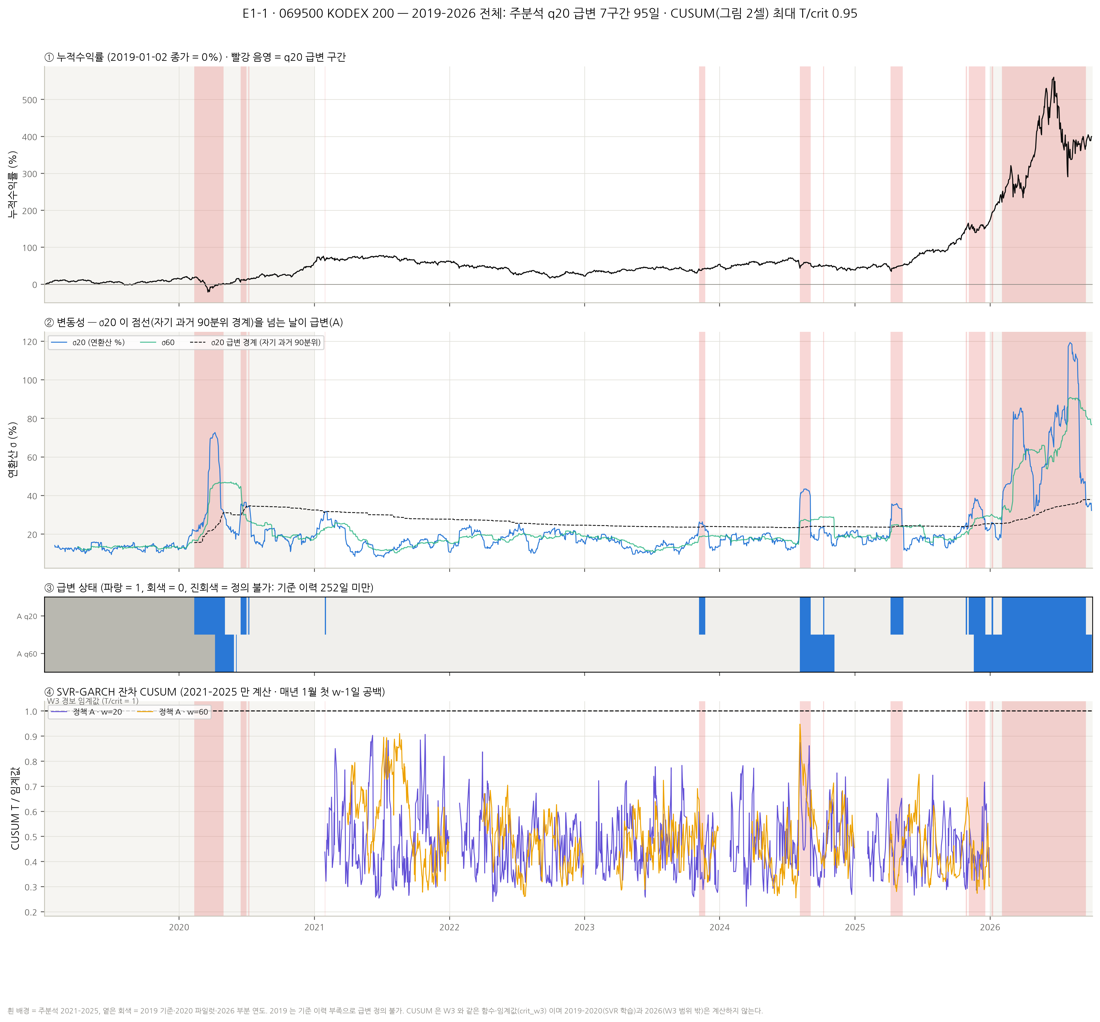

In [5]:
_cap = FG.e1_timeline("069500", "1")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E1_1_069500_timeline"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E1_1_069500_timeline" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 3.3 스케일·지속

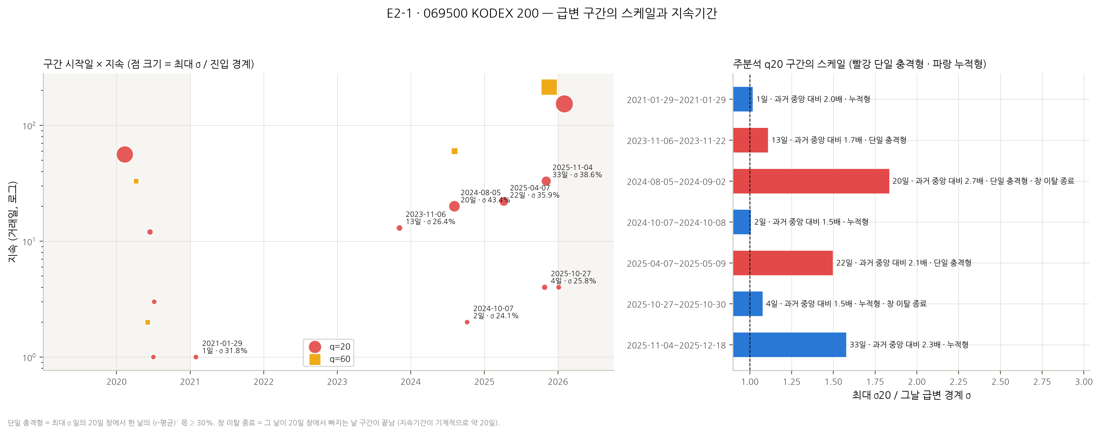

In [6]:
_cap = FG.e2_scale("069500", "1")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E2_1_069500_scale"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E2_1_069500_scale" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 3.4 바텀업 — 왜 잡혔나 (주분석 q20 구간)

In [7]:
# 최대 σ 일의 q 일 창에서 각 날의 분산 기여 (r−r̄)²/Σ, 진입일 수익률, 창 이탈 종료, 시장 공통성(10번 N_A·C1).
XP = X[(X["q"] == 20) & (X["period"] == "PRIMARY")]  # 주분석 q20 구간
display(XP[["interval_id", "start", "end", "duration", "shock_type", "top1_date", "top1_r", "top1_share", "top3", "window_exit_end", "entry_r", "entry_sigma_jump", "other_q_overlap_days", "max_N_A_q20", "C1_days"]].round(3))  # 바텀업 표

,interval_id,start,end,duration,shock_type,top1_date,top1_r,top1_share,top3,window_exit_end,entry_r,entry_sigma_jump,other_q_overlap_days,max_N_A_q20,C1_days
4,069500_q20_005,2021-01-29,2021-01-29,1,누적형,2021-01-08,4.329,0.223,2021-01-08 +4.33% (22%); 2021-01-26 -2.76% (12%); 2021-01-18 -2.34% (9%),False,-2.280,0.761,0,4.0,0
5,069500_q20_006,2023-11-06,2023-11-22,13,단일 충격형,2023-11-06,4.574,0.385,2023-11-06 +4.57% (39%); 2023-10-26 -2.60% (14%); 2023-11-15 +2.15% (8%),False,4.574,5.910,0,5.0,0
6,069500_q20_007,2024-08-05,2024-09-02,20,단일 충격형,2024-08-05,-9.627,0.631,2024-08-05 -9.63% (63%); 2024-08-02 -4.11% (11%); 2024-08-06 +2.74% (6%),True,-9.627,18.594,20,10.0,20
7,069500_q20_008,2024-10-07,2024-10-08,2,누적형,2024-09-26,3.308,0.279,2024-09-26 +3.31% (28%); 2024-09-04 -3.54% (26%); 2024-09-12 +2.26% (14%),False,1.571,0.910,2,3.0,0
8,069500_q20_009,2025-04-07,2025-05-09,22,단일 충격형,2025-04-10,5.980,0.403,2025-04-10 +5.98% (40%); 2025-04-07 -5.87% (32%); 2025-03-31 -2.85% (7%),False,-5.865,8.849,0,12.0,17
9,069500_q20_010,2025-10-27,2025-10-30,4,누적형,2025-09-26,-2.424,0.217,2025-09-26 -2.42% (22%); 2025-10-02 +2.94% (8%); 2025-10-23 -1.06% (7%),True,2.712,0.985,0,3.0,0
10,069500_q20_011,2025-11-04,2025-12-18,33,누적형,2025-11-14,-4.429,0.168,2025-11-14 -4.43% (17%); 2025-11-21 -4.29% (16%); 2025-11-18 -3.37% (10%),False,-2.794,3.468,23,4.0,0


확대 대상: ['069500_q20_011', '069500_q20_009', '069500_q20_007']


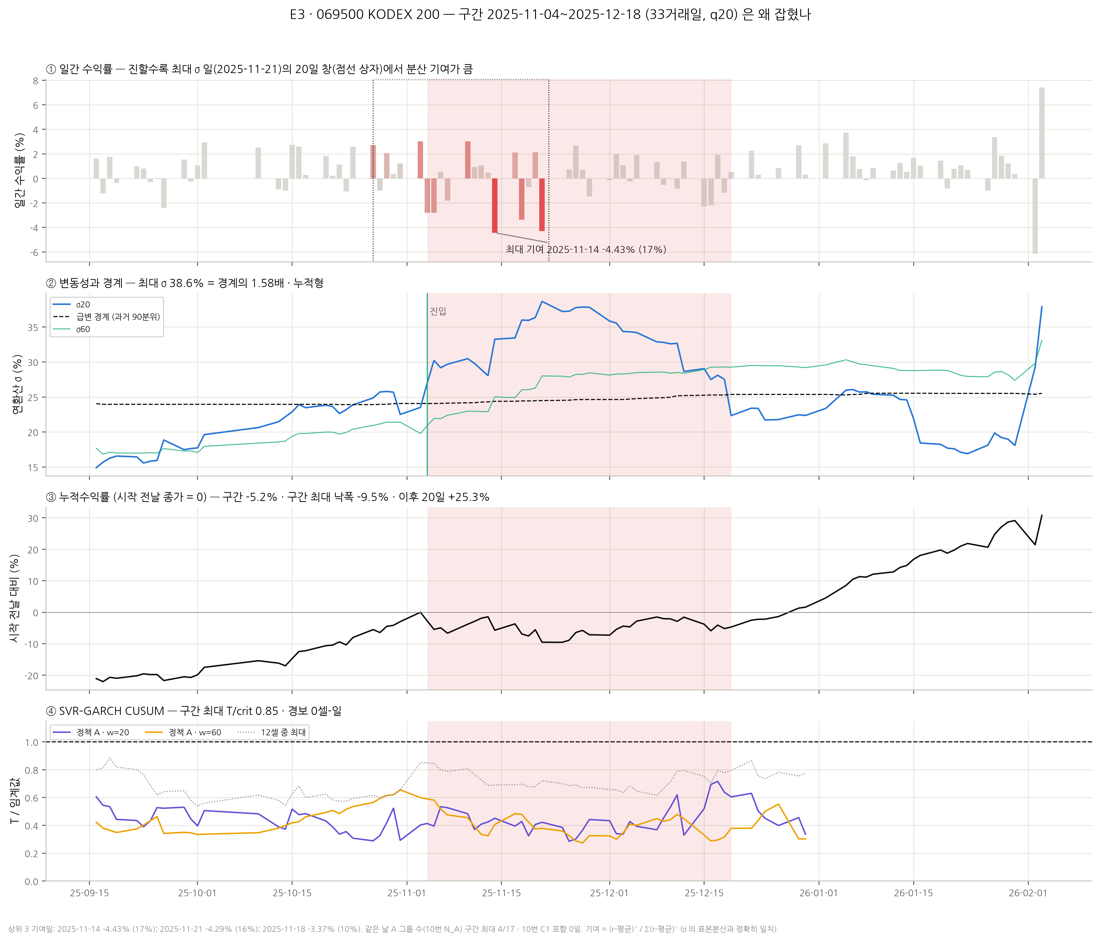

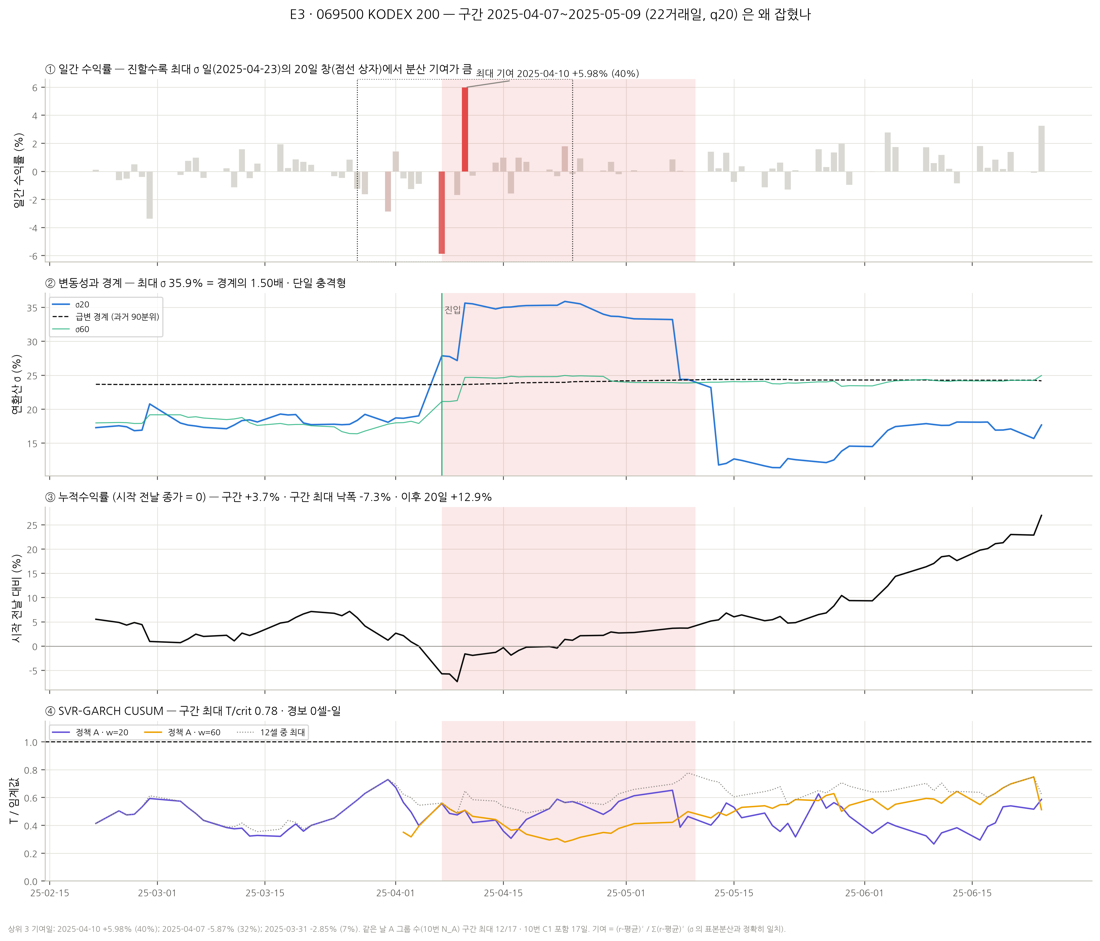

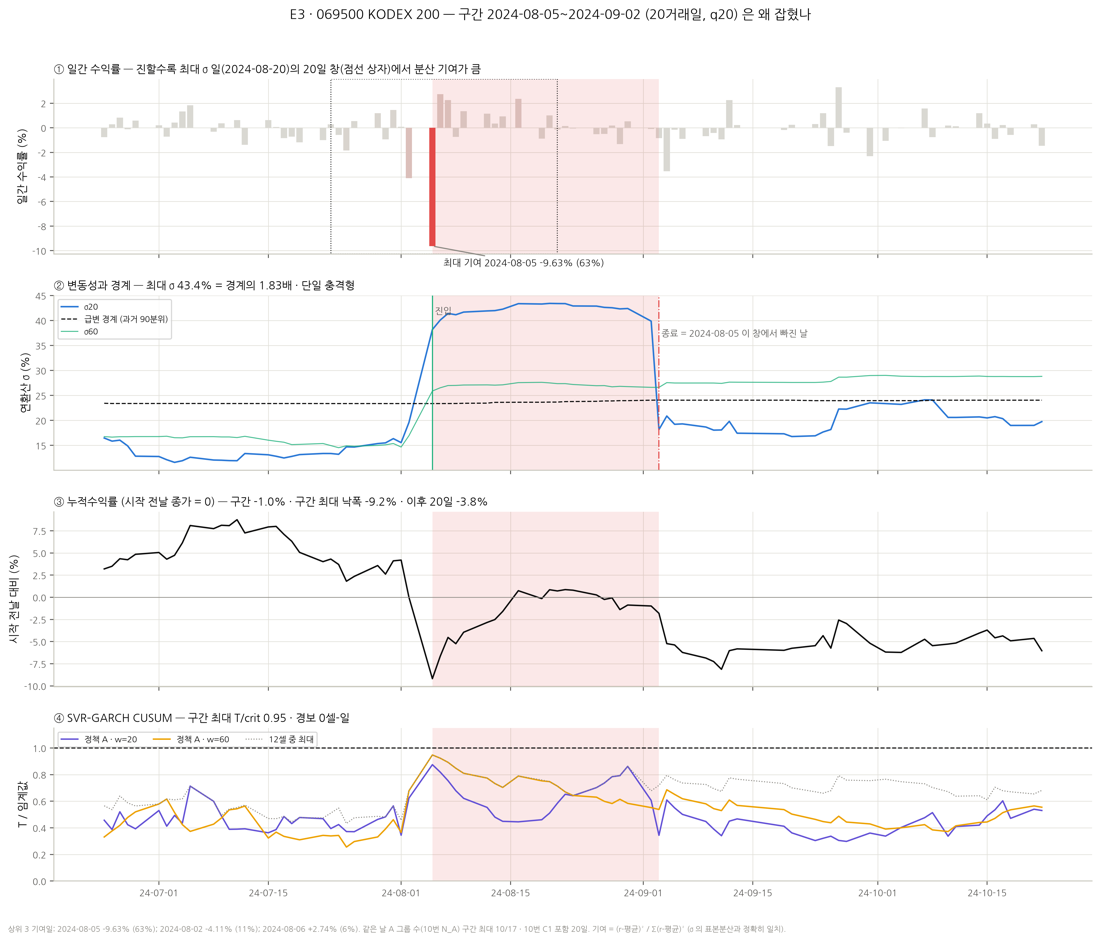

In [8]:
# 확대 대상: 주분석 q20 구간 중 지속 상위 3개 (동률은 시작일 순, 결과를 보고 바꾸지 않는 표시 규칙).
ZOOM = FG.zoom_targets("069500")  # 구간 ID 목록
print("확대 대상:", ZOOM)  # 대상 출력
for _iv in ZOOM:  # 구간마다
    CAP[f"E3_1_{_iv}"] = FG.e3_bottomup("069500", _iv, "1")  # 바텀업 4층 확대 그림
    display(Image(data=preview(FIGDIR / f"E3_1_{_iv}.png")))  # 미리보기

### 3.5 누적수익률

In [9]:
# 구간 수익률·최대 낙폭은 구간 시작 전날 종가 기준, 앞뒤 20거래일 수익률 (%).
display(XP[["interval_id", "start", "end", "ret_pre20_pct", "ret_interval_pct", "max_drawdown_pct", "ret_post20_pct"]].round(2))  # 누적수익률 표

,interval_id,start,end,ret_pre20_pct,ret_interval_pct,max_drawdown_pct,ret_post20_pct
4,069500_q20_005,2021-01-29,2021-01-29,8.88,-2.25,-2.25,3.69
5,069500_q20_006,2023-11-06,2023-11-22,0.03,5.84,-2.89,4.09
6,069500_q20_007,2024-08-05,2024-09-02,-7.49,-0.98,-9.18,-3.79
7,069500_q20_008,2024-10-07,2024-10-08,-5.39,0.81,-0.76,-1.06
8,069500_q20_009,2025-04-07,2025-05-09,-1.96,3.71,-7.31,12.86
9,069500_q20_010,2025-10-27,2025-10-30,16.36,4.22,-0.99,-1.69
10,069500_q20_011,2025-11-04,2025-12-18,25.78,-5.19,-9.55,25.29


### 3.6 SVR–GARCH CUSUM

In [10]:
# 구간별 12셀(3정책 × 4창) 최대 T/crit 와 경보 셀-일 수, 2021–2025 급변일 vs 나머지 날 분포.
RC = [c for c in X.columns if c.startswith("maxR_")]  # 셀별 최대 비율 열
display(XP[["interval_id", "start", "end", "cusum_coverage_A20", "cusum_maxR_any", "cusum_alarm_days_any"] + RC].round(2))  # 구간별 CUSUM
IO = R["inside_outside"]  # 안팎 분포
display(IO[IO["ticker"] == "069500"].pivot_table(index=["policy", "w"], columns="side", values=["median_R", "max_R", "alarm_days"]).round(3))  # 셀별 안팎

,interval_id,start,end,cusum_coverage_A20,cusum_maxR_any,cusum_alarm_days_any,maxR_A_20,maxR_A_30,maxR_A_60,maxR_A_120,maxR_B_20,maxR_B_30,maxR_B_60,maxR_B_120,maxR_base_20,maxR_base_30,maxR_base_60,maxR_base_120
4,069500_q20_005,2021-01-29,2021-01-29,1.0,0.65,0,0.44,NaN,NaN,NaN,0.65,NaN,NaN,NaN,0.57,NaN,NaN,NaN
5,069500_q20_006,2023-11-06,2023-11-22,1.0,0.81,0,0.60,0.57,0.65,0.81,0.60,0.49,0.54,0.65,0.52,0.44,0.49,0.50
6,069500_q20_007,2024-08-05,2024-09-02,1.0,0.95,0,0.87,0.90,0.95,0.89,0.78,0.72,0.65,0.57,0.65,0.61,0.53,0.51
7,069500_q20_008,2024-10-07,2024-10-08,1.0,0.73,0,0.51,0.39,0.42,0.73,0.46,0.37,0.44,0.31,0.40,0.41,0.39,0.30
8,069500_q20_009,2025-04-07,2025-05-09,1.0,0.78,0,0.65,0.78,0.56,NaN,0.63,0.61,0.50,NaN,0.70,0.61,0.59,NaN
9,069500_q20_010,2025-10-27,2025-10-30,1.0,0.62,0,0.52,0.45,0.62,0.38,0.38,0.41,0.39,0.34,0.47,0.47,0.39,0.62
10,069500_q20_011,2025-11-04,2025-12-18,1.0,0.85,0,0.72,0.58,0.59,0.54,0.79,0.74,0.85,0.44,0.79,0.79,0.84,0.72


alarm_days          max_R         median_R        
side            A20 날 비 A20 날  A20 날 비 A20 날    A20 날 비 A20 날
policy w                                                     
A      20         0.0     0.0  0.875   0.907    0.464   0.455
       30         0.0     0.0  0.904   0.892    0.451   0.455
       60         0.0     0.0  0.948   0.910    0.452   0.474
       120        0.0     0.0  0.888   1.000    0.532   0.489
B      20         0.0     0.0  0.795   0.913    0.481   0.440
       30         0.0     0.0  0.736   0.884    0.425   0.422
       60         0.0     0.0  0.849   0.852    0.433   0.420
       120        0.0     0.0  0.648   0.785    0.380   0.361
base   20         0.0     0.0  0.789   0.937    0.470   0.453
       30         0.0     0.0  0.795   0.857    0.418   0.449
       60         0.0     0.0  0.839   0.899    0.464   0.447
       120        0.0     0.0  0.721   0.915    0.508   0.422

**해석 — KOSPI200 (069500).**

*① 급변 구간 (전체 연도).*
- q20 기준으로 2020 파일럿 4구간, 주분석 2021–2025 **7구간 95일**, 2026 2구간이 나왔다.
- q60 은 주분석에서 2구간이다. 2024-08-05~11-05 (60일), 그리고 2025-11-18 에 시작해 데이터 끝(2026-10-02)까지 이어지는 214일 구간이다.

*② 스케일·지속.*
- 주분석에서 가장 큰 구간은 **2024-08-05~09-02 (20일)** 이다. 최대 σ20 은 43.4% 로, 그날 경계의 1.83배이고 과거 중앙 σ 의 2.7배다.
- 가장 긴 구간은 **2025-11-04~12-18 (33일)** 이다.
- 2021-01-29 (1일), 2024-10-07~08 (2일), 2025-10-27~30 (4일) 은 최대 σ 가 경계의 1.01–1.08배다. 경계를 겨우 넘은 짧은 구간이다.

*③ 바텀업 — 왜 잡혔나.*
- **2024-08**: 하루(2024-08-05, −9.63%)가 최대 σ 일 창 분산의 **63%** 를 만든 단일 충격형이다. 구간은 그날이 20일 창에서 빠지는 날(09-03)에 정확히 끝났다(창 이탈 종료). 따라서 20일이라는 지속기간은 시장이 20일간 흔들렸다는 뜻이 아니다. **충격 하루가 창에 머문 기간**이다.
- **2025-04**: 2025-04-07 −5.87% (32%) 와 04-10 +5.98% (40%) 의 급락·급반등 두 날이 만들었다.
- **2025-11~12**: 최대 기여일 몫이 17% 인 누적형이다. −4% 안팎의 날이 여러 번 이어졌다.
- 같은 날 A 인 노출 그룹 수(10번 N_A)는 2024-08 에 최대 10, 2025-04 에 12 로 시장 공통 급변이었다 (C1 포함 20일·17일). 2025-11~12 는 최대 4 로 **국내 주식 고유**의 급변이다 (C1 0일).

*④ 누적수익률.*
- 2024-08 구간: 첫날 −9.2% 낙폭 뒤 회복해 구간 수익률 −1.0%. 구간 전 20일 −7.5%, 후 20일 −3.8%.
- 2025-04 구간: +3.7%. 구간 후 20일 +12.9% 로 반등이 이어졌다.
- 2025-11~12 구간: 직전 20일 +25.8% 의 급등 뒤에 왔다. 구간 수익률 −5.2%, 최대 낙폭 −9.5% 다. **급락 국면만이 아니라 급등 뒤의 흔들림도 급변으로 잡힌다.**

*⑤ SVR–GARCH CUSUM.*
- 2021–2025 동안 069500 은 12개 셀(3정책 × 4창) **어디에서도 경보가 0일**이다.
- 가장 가까이 간 것은 2024-08 구간의 정책 A·w=60 으로, T/crit 0.95 였다.
- 급변일의 T/crit 중앙값(A·w20 0.46)은 나머지 날(0.45)과 거의 같다. 관측 변동성이 급등해도 SVR 예측분산으로 나눈 잔차에서는 그 상승이 흡수된다. W3 의 결론과 같은 방향이다.

*2026 (주분석 제외).* 2026-02-02~09-16 의 153일 구간이 있다 (최대 σ20 119%). 2026-07-31 의 +21.65% 는 102110 +22.06%, 레버리지 122630 +38.4%, 인버스 114800 −25.0% 와 같은 날 함께 나타나 원자료가 서로 일관된다. CUSUM 은 2026 을 계산하지 않았다.

## 4. 229200 — 선정 · 급변 구간 · 스케일·지속 · 바텀업 · 누적수익률 · CUSUM

### 4.1 ETF 선정

**왜 이 ETF 인가 (코스닥 확장).** KODEX 코스닥150 은 같은 국내 주식이지만 성장·중소형 비중이 크다. W3 의 S1 은 069500 과 229200 의 쌍이었다. 국내 주식 안에서 급변이 같이 오는지, 코스닥만 따로 오는지를 본다.

### 4.2 급변 구간 — 전체 연도 (2019–2026)

In [11]:
# 229200 의 q20·q60 급변 구간 전부 (전체 달력에서 한 번에 추출, 기간 지위는 시작일 기준 태그).
X = IV[IV["ticker"] == "229200"]  # 이 ETF 의 구간
display(X[["interval_id", "q", "period", "start", "end", "duration", "primary_days", "right_censored_data_end", "peak_date", "peak_sigma", "peak_U", "peak_over_boundary", "peak_over_past_median"]].round(3))  # 구간·스케일 표
display(R["summary"][R["summary"]["ticker"] == "229200"])  # 기간 지위별 요약

,interval_id,q,period,start,end,duration,primary_days,right_censored_data_end,peak_date,peak_sigma,peak_U,peak_over_boundary,peak_over_past_median
17,229200_q20_001,20,PILOT,2020-03-09,2020-04-21,31,0,False,2020-04-06,79.698,1.000,1.989,3.370
18,229200_q20_002,20,PILOT,2020-06-16,2020-06-16,1,0,False,2020-06-16,43.348,0.908,1.003,1.813
19,229200_q20_003,20,PILOT,2020-06-18,2020-06-18,1,0,False,2020-06-18,43.258,0.900,1.000,1.809
20,229200_q20_004,20,PRIMARY,2022-02-16,2022-02-28,9,9,False,2022-02-25,39.125,0.916,1.093,1.655
21,229200_q20_005,20,PRIMARY,2022-03-07,2022-03-07,1,1,False,2022-03-07,36.100,0.900,1.005,1.522
22,229200_q20_006,20,PRIMARY,2022-03-10,2022-03-14,3,3,False,2022-03-10,37.961,0.914,1.052,1.599
23,229200_q20_007,20,PRIMARY,2022-03-17,2022-03-17,1,1,False,2022-03-17,36.859,0.900,1.010,1.549
24,229200_q20_008,20,PRIMARY,2022-06-24,2022-07-20,19,19,False,2022-07-08,43.144,0.956,1.166,1.794
25,229200_q20_009,20,PRIMARY,2022-10-11,2022-10-12,2,2,False,2022-10-11,38.676,0.915,1.042,1.598
26,229200_q20_010,20,PRIMARY,2022-10-14,2022-10-27,10,10,False,2022-10-24,43.238,0.961,1.143,1.778


,ticker,q,period,n,days,primary_days,dur_median,dur_max,peak_sigma_max,single_shock,window_exit,cusum_alarm_intervals
5,229200,20,PILOT,3,33,0,1.0,31,79.697942,2,1,0
6,229200,20,PRIMARY,13,121,121,9.0,24,65.849294,3,4,0
7,229200,20,PARTIAL_NON_BLIND,3,133,0,62.0,69,96.653147,2,1,0
8,229200,60,PILOT,1,29,0,29.0,29,51.802483,0,0,0
9,229200,60,PRIMARY,6,126,126,13.0,58,43.482030,3,1,0
10,229200,60,PARTIAL_NON_BLIND,1,168,0,168.0,168,78.494585,0,0,0


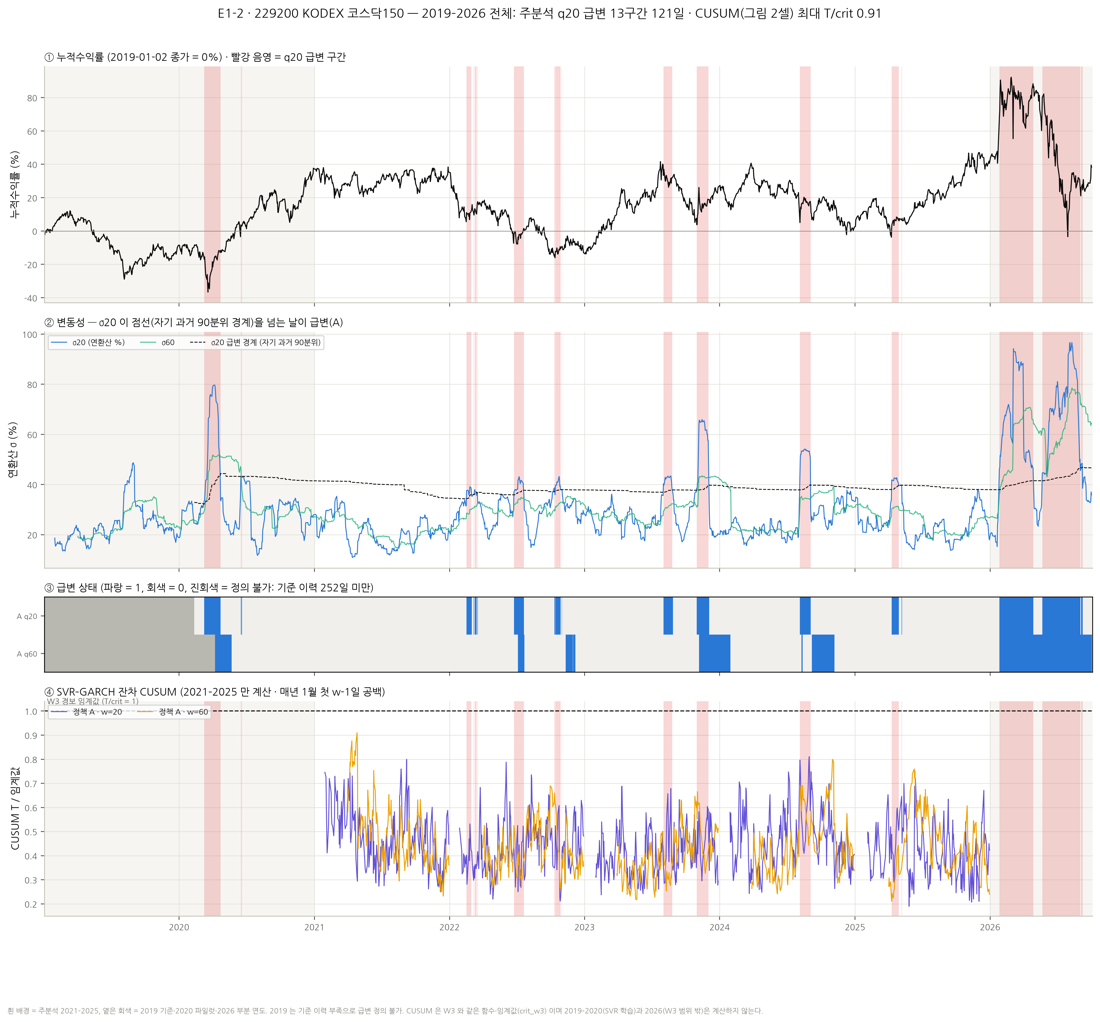

In [12]:
_cap = FG.e1_timeline("229200", "2")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E1_2_229200_timeline"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E1_2_229200_timeline" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 4.3 스케일·지속

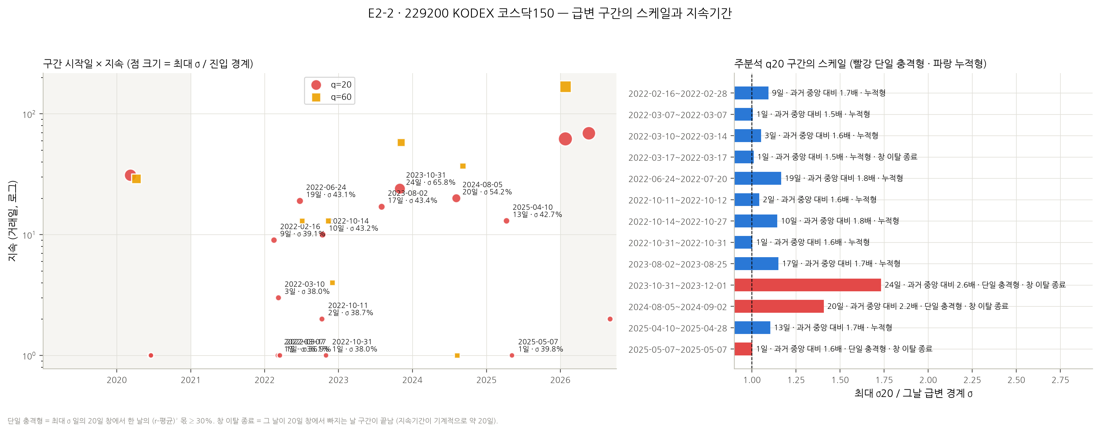

In [13]:
_cap = FG.e2_scale("229200", "2")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E2_2_229200_scale"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E2_2_229200_scale" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 4.4 바텀업 — 왜 잡혔나 (주분석 q20 구간)

In [14]:
# 최대 σ 일의 q 일 창에서 각 날의 분산 기여 (r−r̄)²/Σ, 진입일 수익률, 창 이탈 종료, 시장 공통성(10번 N_A·C1).
XP = X[(X["q"] == 20) & (X["period"] == "PRIMARY")]  # 주분석 q20 구간
display(XP[["interval_id", "start", "end", "duration", "shock_type", "top1_date", "top1_r", "top1_share", "top3", "window_exit_end", "entry_r", "entry_sigma_jump", "other_q_overlap_days", "max_N_A_q20", "C1_days"]].round(3))  # 바텀업 표

,interval_id,start,end,duration,shock_type,top1_date,top1_r,top1_share,top3,window_exit_end,entry_r,entry_sigma_jump,other_q_overlap_days,max_N_A_q20,C1_days
20,229200_q20_004,2022-02-16,2022-02-28,9,누적형,2022-02-16,5.062,0.237,2022-02-16 +5.06% (24%); 2022-01-27 -4.39% (15%); 2022-02-25 +3.76% (13%),False,5.062,6.152,0,5.0,0
21,229200_q20_005,2022-03-07,2022-03-07,1,누적형,2022-02-16,5.062,0.278,2022-02-16 +5.06% (28%); 2022-02-25 +3.76% (16%); 2022-02-24 -3.14% (9%),False,-2.050,0.405,0,4.0,0
22,229200_q20_006,2022-03-10,2022-03-14,3,누적형,2022-02-16,5.062,0.230,2022-02-16 +5.06% (23%); 2022-02-25 +3.76% (13%); 2022-03-10 +3.39% (10%),False,3.391,2.053,0,5.0,0
23,229200_q20_007,2022-03-17,2022-03-17,1,누적형,2022-02-16,5.062,0.204,2022-02-16 +5.06% (20%); 2022-02-24 -3.14% (13%); 2022-02-25 +3.76% (10%),True,2.726,0.365,0,6.0,0
24,229200_q20_008,2022-06-24,2022-07-20,19,누적형,2022-06-24,5.674,0.273,2022-06-24 +5.67% (27%); 2022-07-05 +4.41% (17%); 2022-06-13 -4.60% (12%),False,5.674,7.327,12,7.0,0
25,229200_q20_009,2022-10-11,2022-10-12,2,누적형,2022-10-04,3.708,0.172,2022-10-04 +3.71% (17%); 2022-10-06 +3.12% (13%); 2022-09-26 -4.22% (11%),False,-3.812,1.734,0,9.0,2
26,229200_q20_010,2022-10-14,2022-10-27,10,누적형,2022-10-14,4.529,0.164,2022-10-14 +4.53% (16%); 2022-10-04 +3.71% (11%); 2022-09-26 -4.22% (11%),False,4.529,3.748,0,8.0,0
27,229200_q20_011,2022-10-31,2022-10-31,1,누적형,2022-10-14,4.529,0.171,2022-10-14 +4.53% (17%); 2022-10-11 -3.81% (15%); 2022-10-04 +3.71% (11%),False,1.346,0.182,0,6.0,0
28,229200_q20_012,2023-08-02,2023-08-25,17,누적형,2023-08-02,-4.684,0.141,2023-08-02 -4.68% (14%); 2023-07-26 -4.12% (11%); 2023-07-27 -3.98% (10%),False,-4.684,4.644,0,4.0,0
29,229200_q20_013,2023-10-31,2023-12-01,24,단일 충격형,2023-11-06,13.657,0.567,2023-11-06 +13.66% (57%); 2023-11-02 +5.19% (8%); 2023-11-07 -5.01% (8%),True,-3.645,1.535,20,6.0,0


확대 대상: ['229200_q20_013', '229200_q20_014', '229200_q20_008']


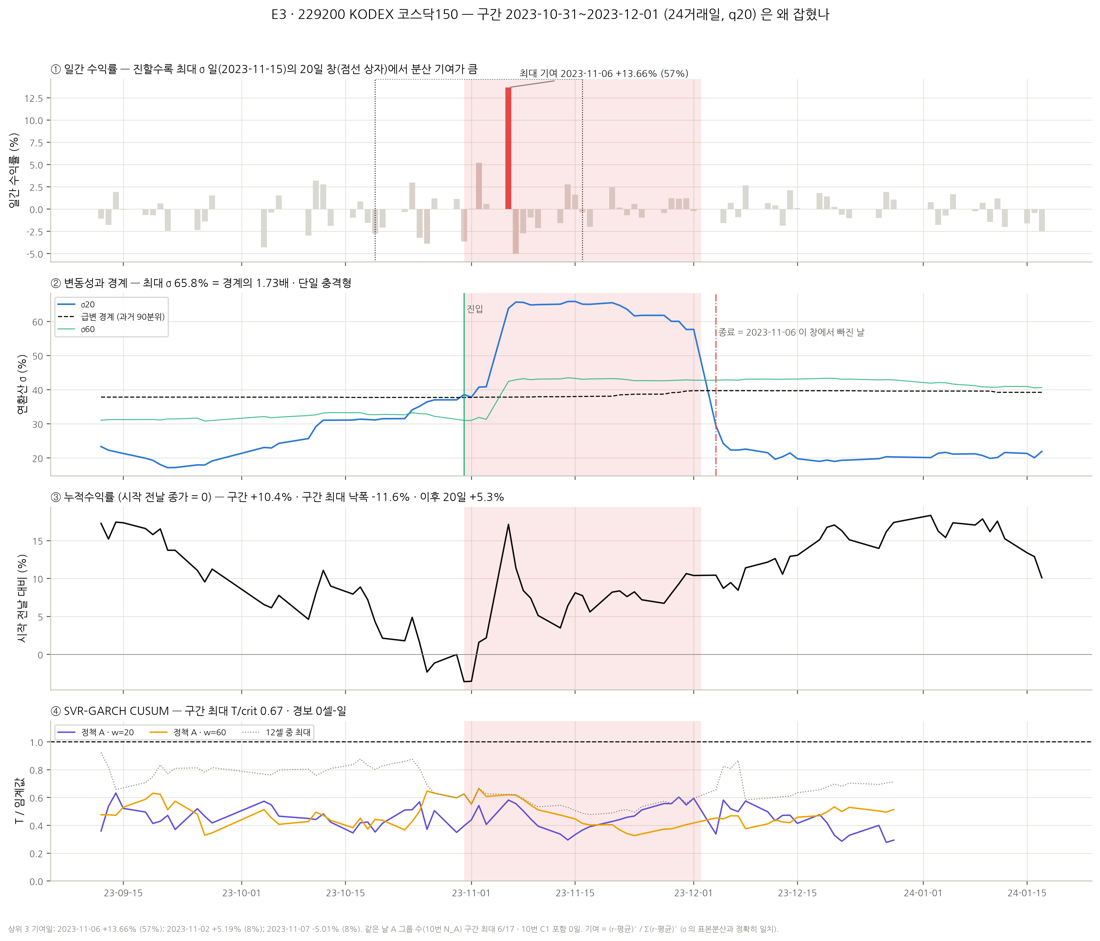

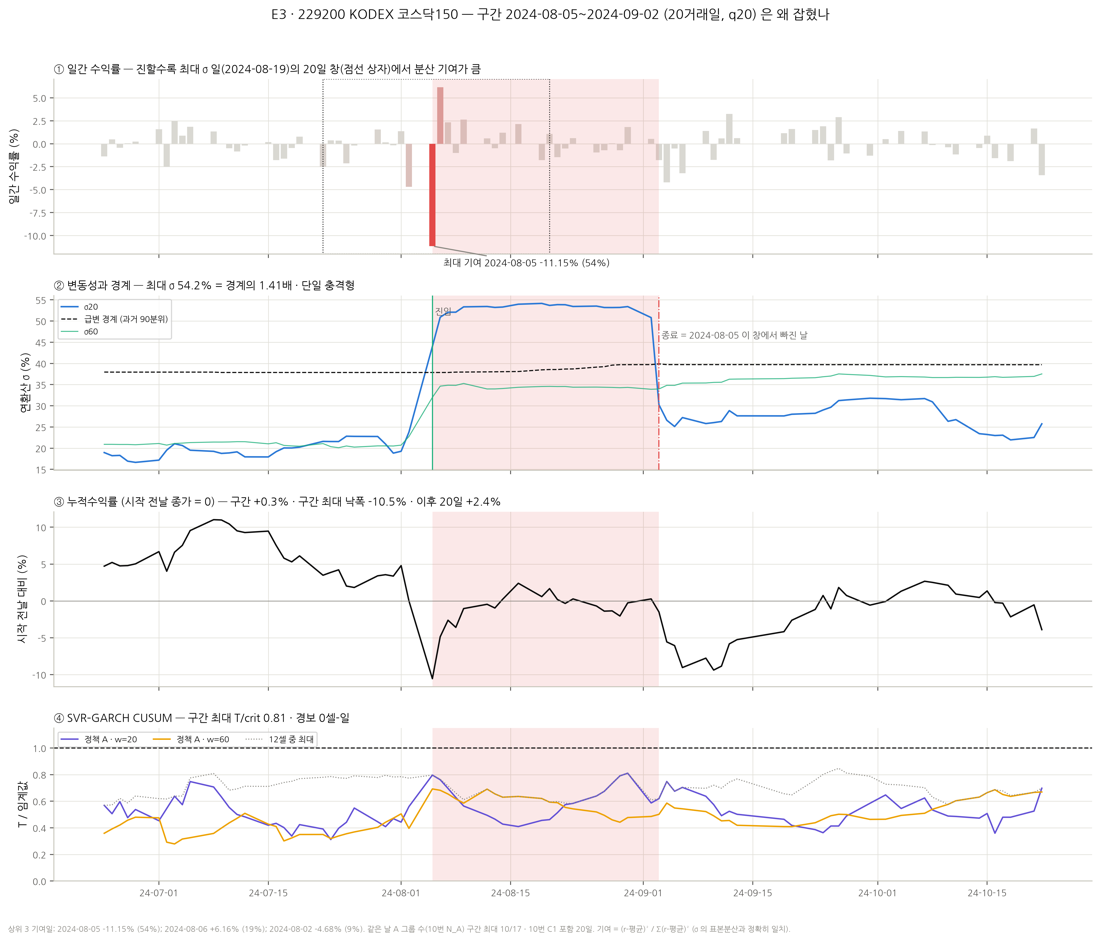

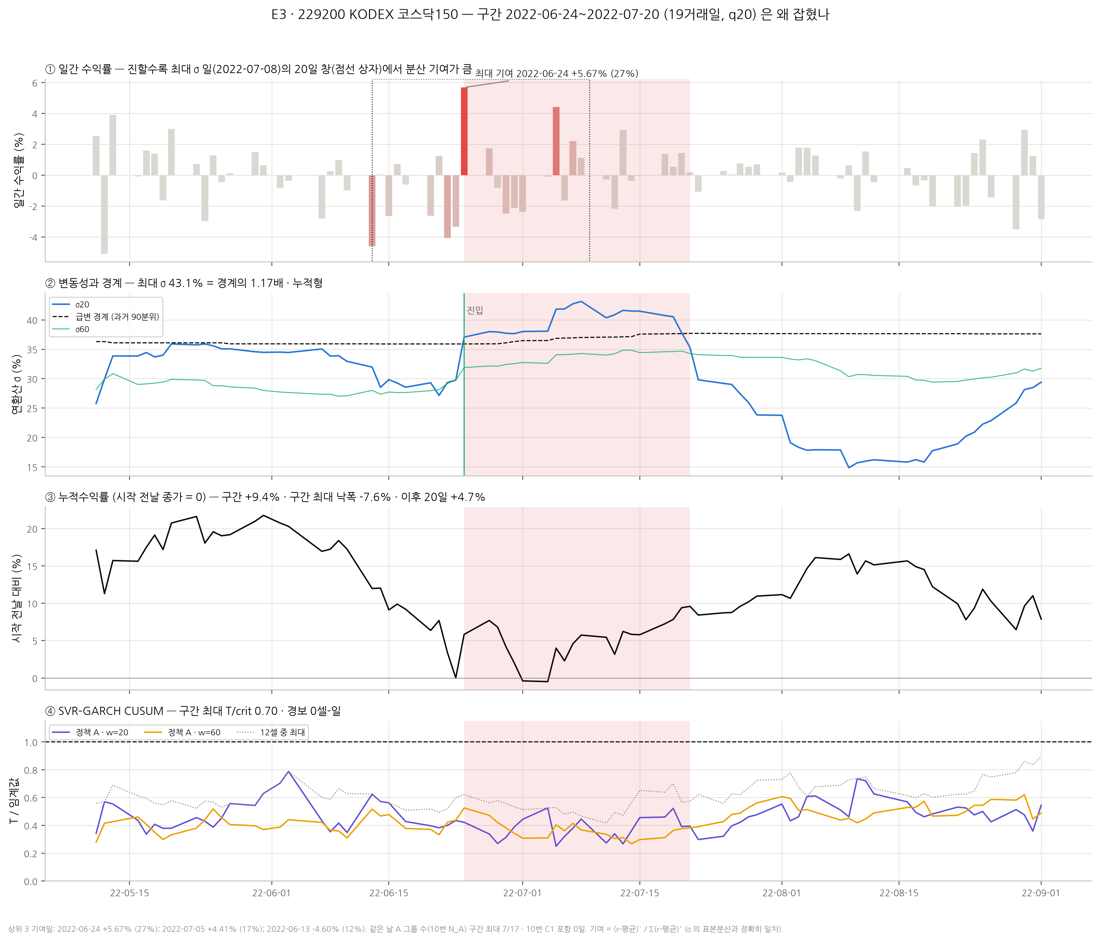

In [15]:
# 확대 대상: 주분석 q20 구간 중 지속 상위 3개 (동률은 시작일 순, 결과를 보고 바꾸지 않는 표시 규칙).
ZOOM = FG.zoom_targets("229200")  # 구간 ID 목록
print("확대 대상:", ZOOM)  # 대상 출력
for _iv in ZOOM:  # 구간마다
    CAP[f"E3_2_{_iv}"] = FG.e3_bottomup("229200", _iv, "2")  # 바텀업 4층 확대 그림
    display(Image(data=preview(FIGDIR / f"E3_2_{_iv}.png")))  # 미리보기

### 4.5 누적수익률

In [16]:
# 구간 수익률·최대 낙폭은 구간 시작 전날 종가 기준, 앞뒤 20거래일 수익률 (%).
display(XP[["interval_id", "start", "end", "ret_pre20_pct", "ret_interval_pct", "max_drawdown_pct", "ret_post20_pct"]].round(2))  # 누적수익률 표

,interval_id,start,end,ret_pre20_pct,ret_interval_pct,max_drawdown_pct,ret_post20_pct
20,229200_q20_004,2022-02-16,2022-02-28,-15.72,5.57,-3.80,5.03
21,229200_q20_005,2022-03-07,2022-03-07,0.08,-2.03,-2.03,6.96
22,229200_q20_006,2022-03-10,2022-03-14,-2.72,0.82,-2.54,2.76
23,229200_q20_007,2022-03-17,2022-03-17,5.79,2.76,0.00,-1.57
24,229200_q20_008,2022-06-24,2022-07-20,-15.30,9.40,-7.60,4.68
25,229200_q20_009,2022-10-11,2022-10-12,-10.57,-2.61,-3.74,6.51
26,229200_q20_010,2022-10-14,2022-10-27,-17.92,7.95,-4.12,4.84
27,229200_q20_011,2022-10-31,2022-10-31,3.67,1.36,0.00,1.05
28,229200_q20_012,2023-08-02,2023-08-25,13.02,-5.78,-9.63,-7.02
29,229200_q20_013,2023-10-31,2023-12-01,-9.97,10.40,-11.65,5.30


### 4.6 SVR–GARCH CUSUM

In [17]:
# 구간별 12셀(3정책 × 4창) 최대 T/crit 와 경보 셀-일 수, 2021–2025 급변일 vs 나머지 날 분포.
RC = [c for c in X.columns if c.startswith("maxR_")]  # 셀별 최대 비율 열
display(XP[["interval_id", "start", "end", "cusum_coverage_A20", "cusum_maxR_any", "cusum_alarm_days_any"] + RC].round(2))  # 구간별 CUSUM
IO = R["inside_outside"]  # 안팎 분포
display(IO[IO["ticker"] == "229200"].pivot_table(index=["policy", "w"], columns="side", values=["median_R", "max_R", "alarm_days"]).round(3))  # 셀별 안팎

,interval_id,start,end,cusum_coverage_A20,cusum_maxR_any,cusum_alarm_days_any,maxR_A_20,maxR_A_30,maxR_A_60,maxR_A_120,maxR_B_20,maxR_B_30,maxR_B_60,maxR_B_120,maxR_base_20,maxR_base_30,maxR_base_60,maxR_base_120
20,229200_q20_004,2022-02-16,2022-02-28,1.0,0.53,0,0.53,0.51,NaN,NaN,0.40,0.34,NaN,NaN,0.41,0.32,NaN,NaN
21,229200_q20_005,2022-03-07,2022-03-07,1.0,0.40,0,0.30,0.26,NaN,NaN,0.33,0.37,NaN,NaN,0.32,0.40,NaN,NaN
22,229200_q20_006,2022-03-10,2022-03-14,1.0,0.44,0,0.36,0.32,NaN,NaN,0.42,0.37,NaN,NaN,0.43,0.44,NaN,NaN
23,229200_q20_007,2022-03-17,2022-03-17,1.0,0.45,0,0.40,0.32,NaN,NaN,0.43,0.24,NaN,NaN,0.45,0.32,NaN,NaN
24,229200_q20_008,2022-06-24,2022-07-20,1.0,0.70,0,0.53,0.56,0.53,0.50,0.62,0.51,0.33,0.35,0.70,0.58,0.56,0.50
25,229200_q20_009,2022-10-11,2022-10-12,1.0,0.81,0,0.35,0.47,0.66,0.47,0.36,0.36,0.72,0.30,0.60,0.64,0.81,0.37
26,229200_q20_010,2022-10-14,2022-10-27,1.0,0.83,0,0.61,0.52,0.61,0.49,0.52,0.44,0.69,0.33,0.60,0.68,0.83,0.44
27,229200_q20_011,2022-10-31,2022-10-31,1.0,0.65,0,0.30,0.31,0.32,0.56,0.57,0.44,0.33,0.32,0.65,0.46,0.57,0.43
28,229200_q20_012,2023-08-02,2023-08-25,1.0,0.85,0,0.68,0.52,0.44,0.37,0.77,0.61,0.48,0.34,0.85,0.79,0.73,0.64
29,229200_q20_013,2023-10-31,2023-12-01,1.0,0.67,0,0.60,0.56,0.67,0.62,0.62,0.58,0.66,0.55,0.55,0.50,0.58,0.45


alarm_days          max_R         median_R        
side            A20 날 비 A20 날  A20 날 비 A20 날    A20 날 비 A20 날
policy w                                                     
A      20         0.0     0.0  0.811   0.800    0.432   0.430
       30         0.0     0.0  0.788   0.843    0.415   0.408
       60         0.0     0.0  0.692   0.910    0.405   0.422
       120        0.0     0.0  0.675   0.789    0.412   0.418
B      20         0.0     0.0  0.768   0.866    0.440   0.445
       30         0.0     0.0  0.614   0.861    0.379   0.418
       60         0.0     0.0  0.724   0.827    0.366   0.410
       120        0.0     0.0  0.616   0.795    0.329   0.383
base   20         0.0     0.0  0.849   0.954    0.478   0.459
       30         0.0     0.0  0.787   0.965    0.450   0.451
       60         0.0     0.0  0.827   0.877    0.480   0.457
       120        0.0     0.0  0.638   0.783    0.427   0.426

### 4.7 확장 — 앞 단계 ETF 와의 겹침

In [18]:
# 단계별 급변일 겹침 (주분석 q20): 069500 과 같은 날, 앞 단계 ETF 중 하나와 같은 날, 앞 단계와 겹치지 않는 단독 구간 수.
display(R["stage"][R["stage"]["order"] <= 2])  # 지금까지의 확장 단계

,order,ticker,stage,A20_days,days_with_069500,days_with_any_prev,intervals,intervals_alone_vs_prev
0,1,069500,S1 기준 (KOSPI200),95,95,0,7,7
1,2,229200,S1 코스닥 확장,121,47,47,13,9


**해석 — 코스닥150 (229200).**
- 주분석 q20 **13구간 121일**. 069500 보다 구간이 많고 짧다. 2022 년에만 8구간(02~03월 4개, 06~07월, 10월 3개)이다.
- 가장 큰 구간은 **2023-10-31~12-01 (24일)** 이다. 최대 σ 65.8% 로 경계의 1.73배다. 하루(2023-11-06, +13.66%)가 창 분산의 57% 를 만들었고, 그날이 창에서 빠지며 끝났다. 같은 날 069500 도 +4.57% 로 급변이 시작됐다.
- 2024-08-05~09-02 (20일) 은 069500 과 날짜가 같다. 2024-08-05 −11.15% (54%) 의 단일 충격이고, 역시 창 이탈로 끝났다.
- 2022 년 구간들은 모두 누적형(최대 기여 16–28%)이다. 한 번의 사건보다 하락장 속 큰 날들이 이어진 결과다.
- **확장 관점**: 229200 의 급변일 121일 중 069500 과 같은 날은 47일이다. 13구간 중 9구간은 069500 의 급변일과 하루도 겹치지 않는다 (코스닥 단독 급변).
- CUSUM: 경보 0. 구간 최대 T/crit 은 2023-08 구간의 0.85 다.

## 5. 148070 — 선정 · 급변 구간 · 스케일·지속 · 바텀업 · 누적수익률 · CUSUM

### 5.1 ETF 선정

**왜 이 ETF 인가 (국채 확장).** KIWOOM 국고채10년은 장기 금리 위험이다. W3 의 S2 에서 처음 들어온 비주식 자산이다. 주식 급변과 금리 급변이 같은 날 오는지 본다.

### 5.2 급변 구간 — 전체 연도 (2019–2026)

In [19]:
# 148070 의 q20·q60 급변 구간 전부 (전체 달력에서 한 번에 추출, 기간 지위는 시작일 기준 태그).
X = IV[IV["ticker"] == "148070"]  # 이 ETF 의 구간
display(X[["interval_id", "q", "period", "start", "end", "duration", "primary_days", "right_censored_data_end", "peak_date", "peak_sigma", "peak_U", "peak_over_boundary", "peak_over_past_median"]].round(3))  # 구간·스케일 표
display(R["summary"][R["summary"]["ticker"] == "148070"])  # 기간 지위별 요약

,interval_id,q,period,start,end,duration,primary_days,right_censored_data_end,peak_date,peak_sigma,peak_U,peak_over_boundary,peak_over_past_median
44,148070_q20_001,20,PILOT,2020-02-18,2020-02-18,1,0,False,2020-02-18,5.435,0.903,1.010,1.453
45,148070_q20_002,20,PILOT,2020-03-09,2020-04-23,33,0,False,2020-03-26,11.690,1.000,2.022,3.001
46,148070_q20_003,20,PRIMARY,2021-04-08,2021-04-08,1,1,False,2021-04-08,5.693,0.905,1.009,1.592
47,148070_q20_004,20,PRIMARY,2021-10-13,2021-11-25,32,32,False,2021-11-02,9.093,0.973,1.612,2.622
48,148070_q20_005,20,PRIMARY,2022-01-13,2022-02-07,15,15,False,2022-01-17,6.506,0.934,1.098,1.816
49,148070_q20_006,20,PRIMARY,2022-02-09,2022-02-15,5,5,False,2022-02-11,6.387,0.934,1.056,1.767
50,148070_q20_007,20,PRIMARY,2022-02-24,2022-03-10,9,9,False,2022-03-02,7.067,0.939,1.160,1.940
51,148070_q20_008,20,PRIMARY,2022-03-14,2022-03-14,1,1,False,2022-03-14,6.164,0.902,1.002,1.672
52,148070_q20_009,20,PRIMARY,2022-03-22,2022-07-12,78,78,False,2022-07-08,10.046,0.981,1.197,2.593
53,148070_q20_010,20,PRIMARY,2022-07-20,2022-07-22,3,3,False,2022-07-22,8.598,0.927,1.021,2.184


,ticker,q,period,n,days,primary_days,dur_median,dur_max,peak_sigma_max,single_shock,window_exit,cusum_alarm_intervals
11,148070,20,PILOT,2,34,0,17.0,33,11.690213,1,0,0
12,148070,20,PRIMARY,19,261,261,5.0,78,14.680121,5,7,0
13,148070,20,PARTIAL_NON_BLIND,2,17,0,8.5,13,10.679643,1,0,0
14,148070,60,PILOT,1,24,0,24.0,24,7.831352,0,0,0
15,148070,60,PRIMARY,15,300,300,5.0,198,11.876617,5,1,0


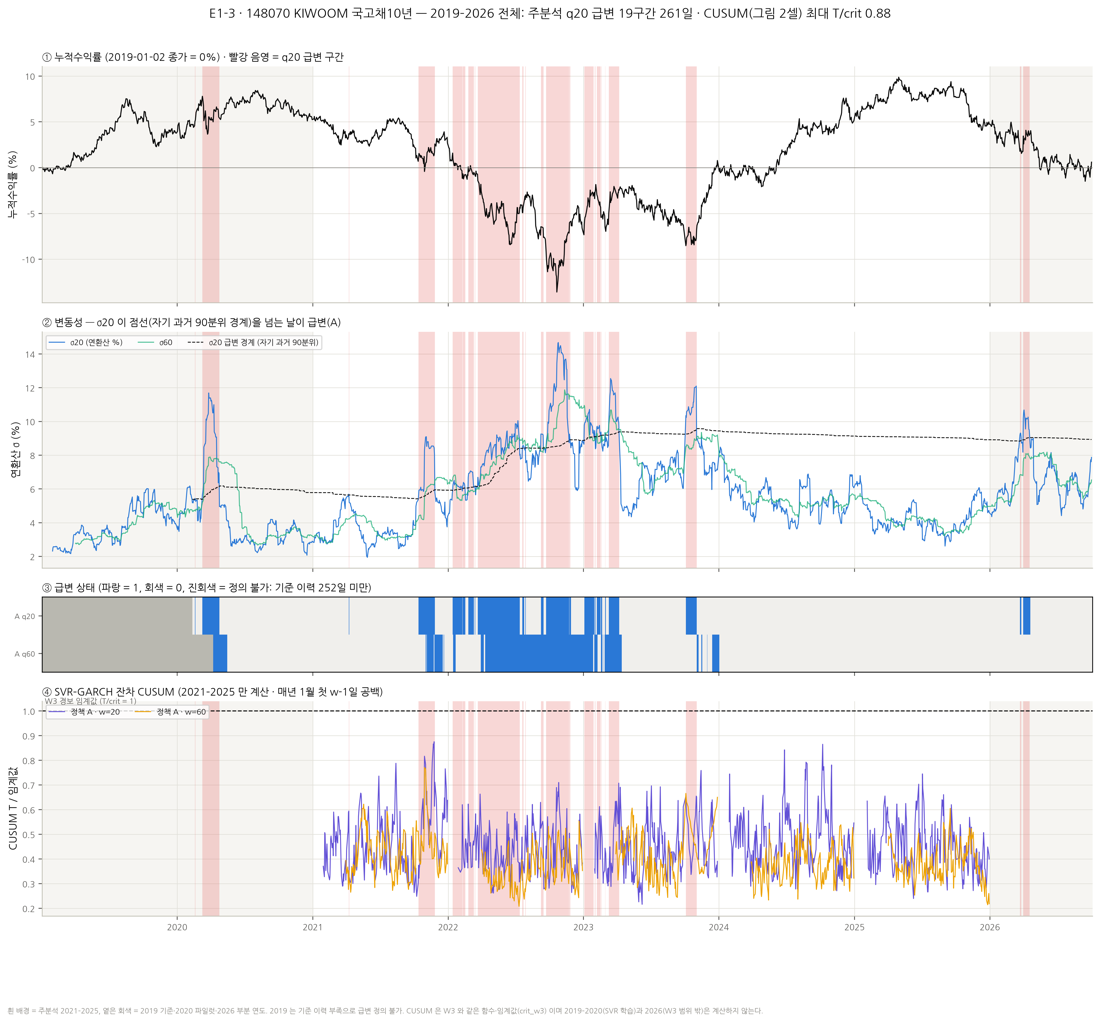

In [20]:
_cap = FG.e1_timeline("148070", "3")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E1_3_148070_timeline"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E1_3_148070_timeline" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 5.3 스케일·지속

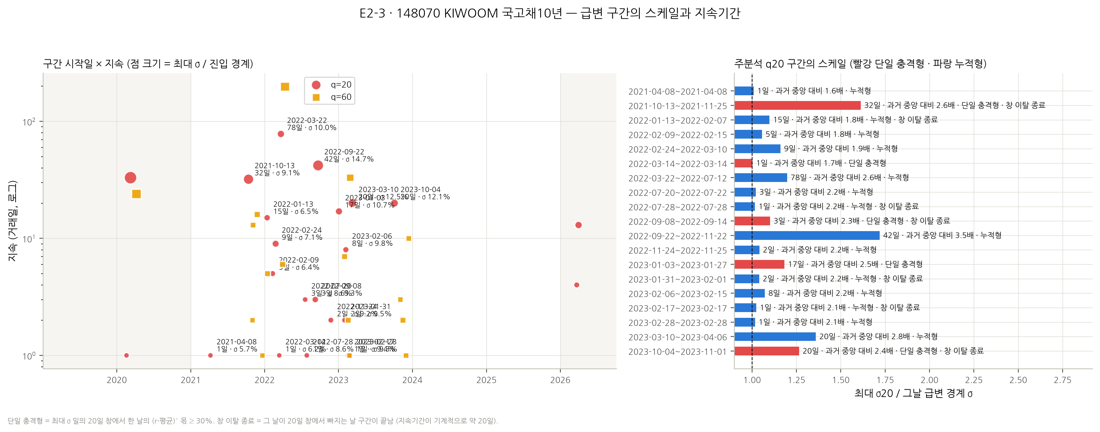

In [21]:
_cap = FG.e2_scale("148070", "3")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E2_3_148070_scale"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E2_3_148070_scale" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 5.4 바텀업 — 왜 잡혔나 (주분석 q20 구간)

In [22]:
# 최대 σ 일의 q 일 창에서 각 날의 분산 기여 (r−r̄)²/Σ, 진입일 수익률, 창 이탈 종료, 시장 공통성(10번 N_A·C1).
XP = X[(X["q"] == 20) & (X["period"] == "PRIMARY")]  # 주분석 q20 구간
display(XP[["interval_id", "start", "end", "duration", "shock_type", "top1_date", "top1_r", "top1_share", "top3", "window_exit_end", "entry_r", "entry_sigma_jump", "other_q_overlap_days", "max_N_A_q20", "C1_days"]].round(3))  # 바텀업 표

,interval_id,start,end,duration,shock_type,top1_date,top1_r,top1_share,top3,window_exit_end,entry_r,entry_sigma_jump,other_q_overlap_days,max_N_A_q20,C1_days
46,148070_q20_003,2021-04-08,2021-04-08,1,누적형,2021-03-30,-0.676,0.194,2021-03-30 -0.68% (19%); 2021-03-12 -0.63% (17%); 2021-03-16 +0.50% (10%),False,0.391,0.138,0,1.0,0
47,148070_q20_004,2021-10-13,2021-11-25,32,단일 충격형,2021-10-29,-1.630,0.383,2021-10-29 -1.63% (38%); 2021-11-01 +0.88% (15%); 2021-10-06 -1.04% (15%),True,0.349,0.232,16,2.0,0
48,148070_q20_005,2022-01-13,2022-02-07,15,누적형,2022-01-06,-0.947,0.196,2022-01-06 -0.95% (20%); 2022-01-12 +0.53% (15%); 2022-01-14 -0.70% (9%),True,0.313,0.173,5,3.0,0
49,148070_q20_006,2022-02-09,2022-02-15,5,누적형,2022-02-08,-0.848,0.182,2022-02-08 -0.85% (18%); 2022-01-12 +0.53% (13%); 2022-01-14 -0.70% (12%),False,0.494,0.306,0,2.0,0
50,148070_q20_007,2022-02-24,2022-03-10,9,누적형,2022-02-24,0.949,0.228,2022-02-24 +0.95% (23%); 2022-02-08 -0.85% (20%); 2022-02-25 -0.54% (8%),False,0.949,1.055,0,5.0,0
51,148070_q20_008,2022-03-14,2022-03-14,1,단일 충격형,2022-02-24,0.949,0.316,2022-02-24 +0.95% (32%); 2022-02-25 -0.54% (10%); 2022-03-02 +0.53% (10%),False,-0.238,0.061,0,5.0,0
52,148070_q20_009,2022-03-22,2022-07-12,78,누적형,2022-07-01,1.337,0.213,2022-07-01 +1.34% (21%); 2022-06-13 -1.08% (17%); 2022-06-15 -1.06% (17%),False,-0.761,0.576,70,7.0,0
53,148070_q20_010,2022-07-20,2022-07-22,3,누적형,2022-07-01,1.337,0.255,2022-07-01 +1.34% (25%); 2022-07-20 -0.86% (18%); 2022-07-08 -0.67% (12%),False,-0.856,0.690,3,5.0,0
54,148070_q20_011,2022-07-28,2022-07-28,1,누적형,2022-07-01,1.337,0.236,2022-07-01 +1.34% (24%); 2022-07-20 -0.86% (20%); 2022-07-08 -0.67% (14%),True,-0.378,0.259,1,2.0,0
55,148070_q20_012,2022-09-08,2022-09-14,3,단일 충격형,2022-08-16,1.239,0.301,2022-08-16 +1.24% (30%); 2022-09-08 +0.99% (20%); 2022-08-25 -1.25% (19%),True,0.988,1.023,3,4.0,0


확대 대상: ['148070_q20_009', '148070_q20_013', '148070_q20_004']


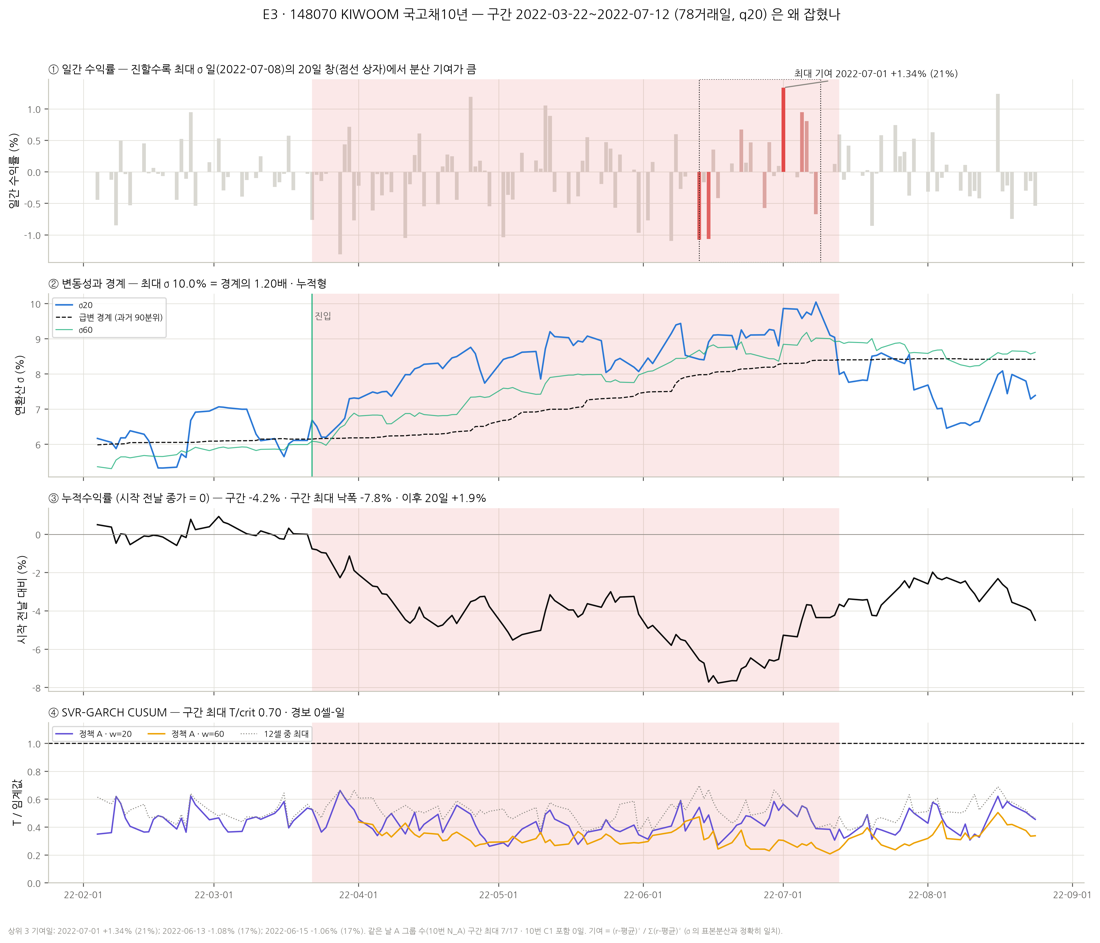

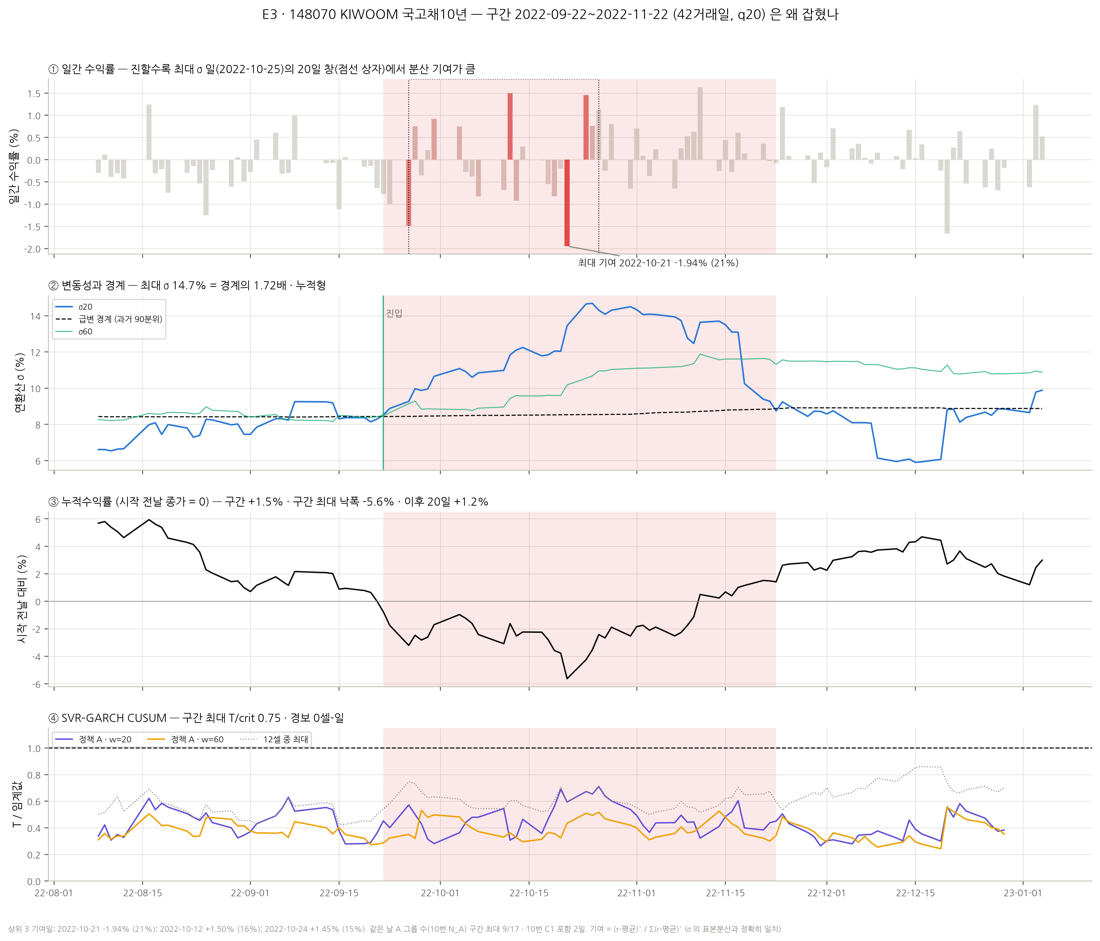

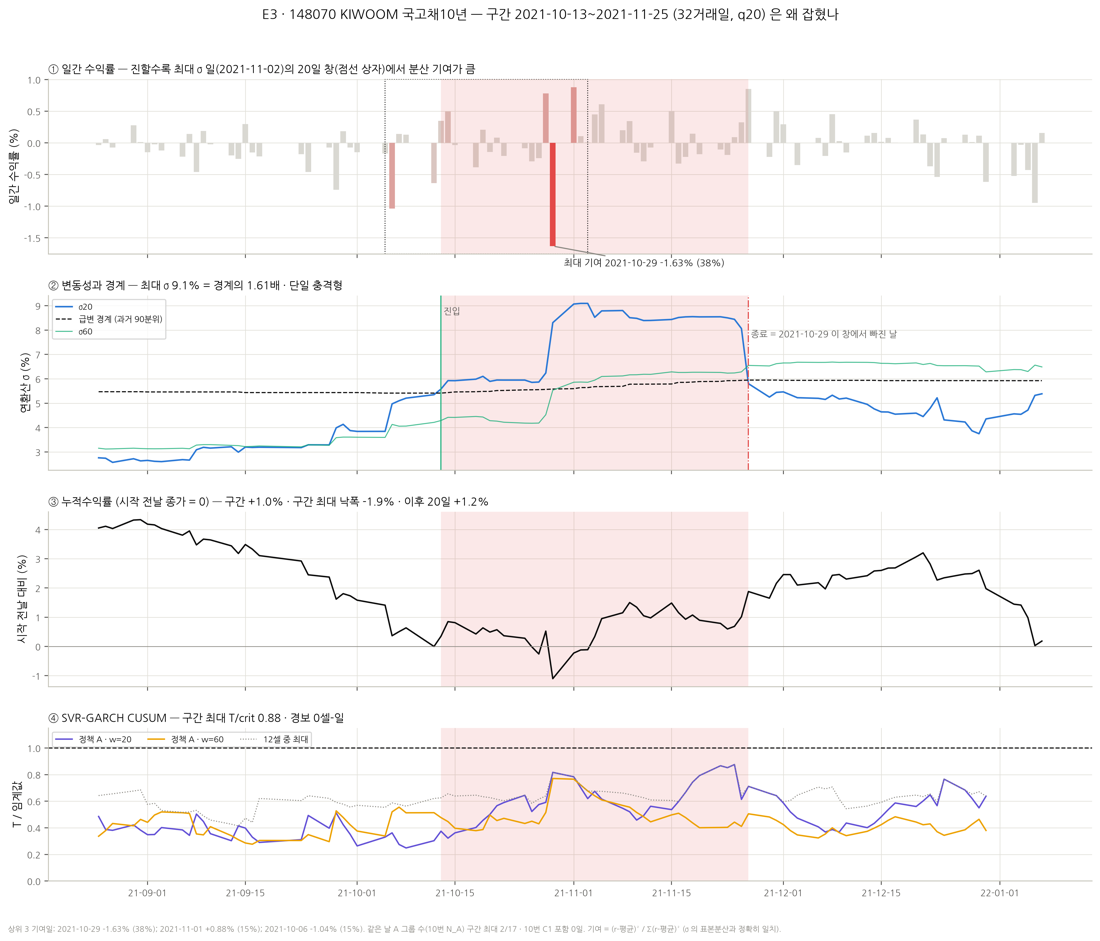

In [23]:
# 확대 대상: 주분석 q20 구간 중 지속 상위 3개 (동률은 시작일 순, 결과를 보고 바꾸지 않는 표시 규칙).
ZOOM = FG.zoom_targets("148070")  # 구간 ID 목록
print("확대 대상:", ZOOM)  # 대상 출력
for _iv in ZOOM:  # 구간마다
    CAP[f"E3_3_{_iv}"] = FG.e3_bottomup("148070", _iv, "3")  # 바텀업 4층 확대 그림
    display(Image(data=preview(FIGDIR / f"E3_3_{_iv}.png")))  # 미리보기

### 5.5 누적수익률

In [24]:
# 구간 수익률·최대 낙폭은 구간 시작 전날 종가 기준, 앞뒤 20거래일 수익률 (%).
display(XP[["interval_id", "start", "end", "ret_pre20_pct", "ret_interval_pct", "max_drawdown_pct", "ret_post20_pct"]].round(2))  # 누적수익률 표

,interval_id,start,end,ret_pre20_pct,ret_interval_pct,max_drawdown_pct,ret_post20_pct
46,148070_q20_003,2021-04-08,2021-04-08,0.03,0.39,0.00,-0.77
47,148070_q20_004,2021-10-13,2021-11-25,-3.80,1.02,-1.93,1.24
48,148070_q20_005,2022-01-13,2022-02-07,-1.95,-1.57,-1.88,-0.35
49,148070_q20_006,2022-02-09,2022-02-15,-1.87,0.36,-0.56,0.43
50,148070_q20_007,2022-02-24,2022-03-10,-1.33,0.10,-0.99,-3.07
51,148070_q20_008,2022-03-14,2022-03-14,0.16,-0.24,-0.24,-4.40
52,148070_q20_009,2022-03-22,2022-07-12,0.07,-4.22,-7.77,1.87
53,148070_q20_010,2022-07-20,2022-07-22,4.59,-0.30,-0.88,-0.14
54,148070_q20_011,2022-07-28,2022-07-28,4.48,-0.38,-0.38,-3.19
55,148070_q20_012,2022-09-08,2022-09-14,-4.39,0.85,-0.15,-4.16


### 5.6 SVR–GARCH CUSUM

In [25]:
# 구간별 12셀(3정책 × 4창) 최대 T/crit 와 경보 셀-일 수, 2021–2025 급변일 vs 나머지 날 분포.
RC = [c for c in X.columns if c.startswith("maxR_")]  # 셀별 최대 비율 열
display(XP[["interval_id", "start", "end", "cusum_coverage_A20", "cusum_maxR_any", "cusum_alarm_days_any"] + RC].round(2))  # 구간별 CUSUM
IO = R["inside_outside"]  # 안팎 분포
display(IO[IO["ticker"] == "148070"].pivot_table(index=["policy", "w"], columns="side", values=["median_R", "max_R", "alarm_days"]).round(3))  # 셀별 안팎

,interval_id,start,end,cusum_coverage_A20,cusum_maxR_any,cusum_alarm_days_any,maxR_A_20,maxR_A_30,maxR_A_60,maxR_A_120,maxR_B_20,maxR_B_30,maxR_B_60,maxR_B_120,maxR_base_20,maxR_base_30,maxR_base_60,maxR_base_120
46,148070_q20_003,2021-04-08,2021-04-08,1.00,0.60,0,0.59,0.35,0.35,NaN,0.51,0.35,0.60,NaN,0.57,0.40,0.53,NaN
47,148070_q20_004,2021-10-13,2021-11-25,1.00,0.88,0,0.88,0.79,0.77,0.65,0.68,0.55,0.50,0.54,0.73,0.54,0.60,0.71
48,148070_q20_005,2022-01-13,2022-02-07,0.27,0.63,0,0.36,NaN,NaN,NaN,0.63,NaN,NaN,NaN,0.57,NaN,NaN,NaN
49,148070_q20_006,2022-02-09,2022-02-15,1.00,0.57,0,0.57,NaN,NaN,NaN,0.57,NaN,NaN,NaN,0.56,NaN,NaN,NaN
50,148070_q20_007,2022-02-24,2022-03-10,1.00,0.64,0,0.62,0.64,NaN,NaN,0.47,0.41,NaN,NaN,0.42,0.48,NaN,NaN
51,148070_q20_008,2022-03-14,2022-03-14,1.00,0.51,0,0.50,0.51,NaN,NaN,0.40,0.35,NaN,NaN,0.41,0.33,NaN,NaN
52,148070_q20_009,2022-03-22,2022-07-12,1.00,0.70,0,0.66,0.59,0.47,0.27,0.70,0.58,0.47,0.27,0.69,0.56,0.44,0.31
53,148070_q20_010,2022-07-20,2022-07-22,1.00,0.47,0,0.39,0.34,0.35,0.31,0.44,0.39,0.28,0.22,0.47,0.40,0.32,0.26
54,148070_q20_011,2022-07-28,2022-07-28,1.00,0.63,0,0.54,0.31,0.27,0.33,0.56,0.33,0.32,0.25,0.63,0.33,0.33,0.31
55,148070_q20_012,2022-09-08,2022-09-14,1.00,0.59,0,0.55,0.39,0.45,0.28,0.59,0.42,0.31,0.32,0.43,0.45,0.33,0.45


alarm_days          max_R         median_R        
side            A20 날 비 A20 날  A20 날 비 A20 날    A20 날 비 A20 날
policy w                                                     
A      20         0.0     0.0  0.876   0.865    0.458   0.440
       30         0.0     0.0  0.786   0.795    0.429   0.425
       60         0.0     0.0  0.771   0.650    0.370   0.383
       120        0.0     0.0  0.647   0.642    0.375   0.328
B      20         0.0     0.0  0.848   0.814    0.457   0.437
       30         0.0     0.0  0.665   0.842    0.392   0.429
       60         0.0     0.0  0.598   0.875    0.344   0.434
       120        0.0     0.0  0.542   0.720    0.305   0.417
base   20         0.0     0.0  0.940   0.911    0.439   0.441
       30         0.0     0.0  0.764   0.927    0.397   0.434
       60         0.0     0.0  0.641   0.928    0.368   0.465
       120        0.0     0.0  0.705   0.880    0.413   0.437

### 5.7 확장 — 앞 단계 ETF 와의 겹침

In [26]:
# 단계별 급변일 겹침 (주분석 q20): 069500 과 같은 날, 앞 단계 ETF 중 하나와 같은 날, 앞 단계와 겹치지 않는 단독 구간 수.
display(R["stage"][R["stage"]["order"] <= 3])  # 지금까지의 확장 단계

,order,ticker,stage,A20_days,days_with_069500,days_with_any_prev,intervals,intervals_alone_vs_prev
0,1,069500,S1 기준 (KOSPI200),95,95,0,7,7
1,2,229200,S1 코스닥 확장,121,47,47,13,9
2,3,148070,S2 국채10년 확장,261,0,35,19,13


**해석 — 국고채10년 (148070).**
- 주분석 q20 **19구간 261일**. 6종 중 주식이 아닌 자산에서 급변일이 가장 많다. 2022 년에 몰려 있다.
- 가장 긴 구간은 **2022-03-22~07-12 (78일)** 이다. 가장 큰 구간은 **2022-09-22~11-22 (42일, 최대 σ 14.7%, 경계의 1.72배)** 이다. 둘 다 누적형(최대 기여 21%)이다. 금리 급등기에 ±1–2% 의 날이 길게 이어진 결과다.
- **확장 관점**: 148070 의 급변일은 069500 과 **하루도 겹치지 않는다 (0일)**. 앞 단계(069500·229200) 중 하나와 겹친 날은 35일이고, 19구간 중 13구간은 단독이다. 국채 급변은 주식 급변과 다른 시기에 온다.
- 2023-03-10~04-06 (20일) 구간의 CUSUM T/crit 0.94 가 이 ETF 의 최대다. 경보는 없다.

## 6. 153130 — 선정 · 급변 구간 · 스케일·지속 · 바텀업 · 누적수익률 · CUSUM

### 6.1 ETF 선정

**왜 이 ETF 인가 (단기채 확장).** KODEX 단기채권은 듀레이션이 매우 짧다. σ 가 연 0.2–0.6% 수준이라 **절대 수준은 아주 작다**. 급변(A)은 자기 과거 분위로 정의하므로 이런 자산도 급변 구간을 가질 수 있다. W3 의 S3 이다.

### 6.2 급변 구간 — 전체 연도 (2019–2026)

In [27]:
# 153130 의 q20·q60 급변 구간 전부 (전체 달력에서 한 번에 추출, 기간 지위는 시작일 기준 태그).
X = IV[IV["ticker"] == "153130"]  # 이 ETF 의 구간
display(X[["interval_id", "q", "period", "start", "end", "duration", "primary_days", "right_censored_data_end", "peak_date", "peak_sigma", "peak_U", "peak_over_boundary", "peak_over_past_median"]].round(3))  # 구간·스케일 표
display(R["summary"][R["summary"]["ticker"] == "153130"])  # 기간 지위별 요약

,interval_id,q,period,start,end,duration,primary_days,right_censored_data_end,peak_date,peak_sigma,peak_U,peak_over_boundary,peak_over_past_median
83,153130_q20_001,20,PILOT,2020-02-11,2020-02-13,3,0,False,2020-02-11,0.138,0.919,1.027,1.255
84,153130_q20_002,20,PILOT,2020-02-17,2020-02-19,3,0,False,2020-02-17,0.143,0.957,1.061,1.299
85,153130_q20_003,20,PILOT,2020-02-28,2020-04-14,33,0,False,2020-03-23,0.249,1.000,1.742,2.210
86,153130_q20_004,20,PILOT,2020-10-13,2020-11-06,19,0,False,2020-10-20,0.188,0.950,1.241,1.715
87,153130_q20_005,20,PRIMARY,2021-01-12,2021-01-14,3,3,False,2021-01-14,0.178,0.917,1.009,1.631
88,153130_q20_006,20,PRIMARY,2021-01-28,2021-01-29,2,2,False,2021-01-29,0.185,0.929,1.049,1.685
89,153130_q20_007,20,PRIMARY,2021-11-03,2021-11-08,4,4,False,2021-11-03,0.176,0.919,1.043,1.612
90,153130_q20_008,20,PRIMARY,2022-02-15,2022-02-16,2,2,False,2022-02-15,0.168,0.901,1.018,1.514
91,153130_q20_009,20,PRIMARY,2022-03-29,2022-04-05,6,6,False,2022-04-05,0.182,0.951,1.084,1.626
92,153130_q20_010,20,PRIMARY,2022-04-07,2022-04-07,1,1,False,2022-04-07,0.171,0.906,1.018,1.523


,ticker,q,period,n,days,primary_days,dur_median,dur_max,peak_sigma_max,single_shock,window_exit,cusum_alarm_intervals
16,153130,20,PILOT,4,58,0,11.0,33,0.249147,1,2,0
17,153130,20,PRIMARY,21,269,269,6.0,63,2.489804,9,7,0
18,153130,20,PARTIAL_NON_BLIND,3,27,0,7.0,19,0.335739,2,2,0
19,153130,60,PILOT,3,18,0,1.0,16,0.181062,0,0,0
20,153130,60,PRIMARY,10,352,352,8.5,186,1.427373,2,1,0


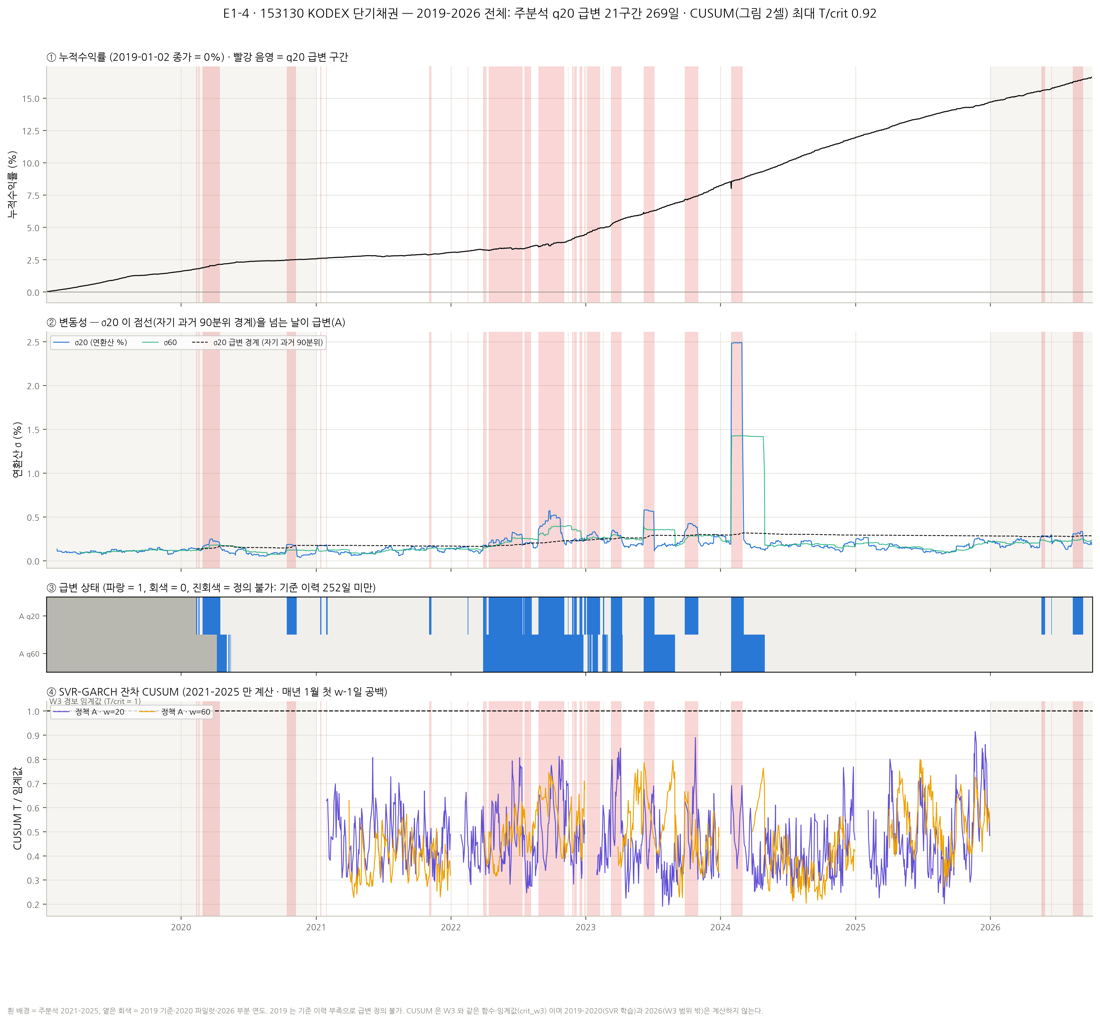

In [28]:
_cap = FG.e1_timeline("153130", "4")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E1_4_153130_timeline"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E1_4_153130_timeline" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 6.3 스케일·지속

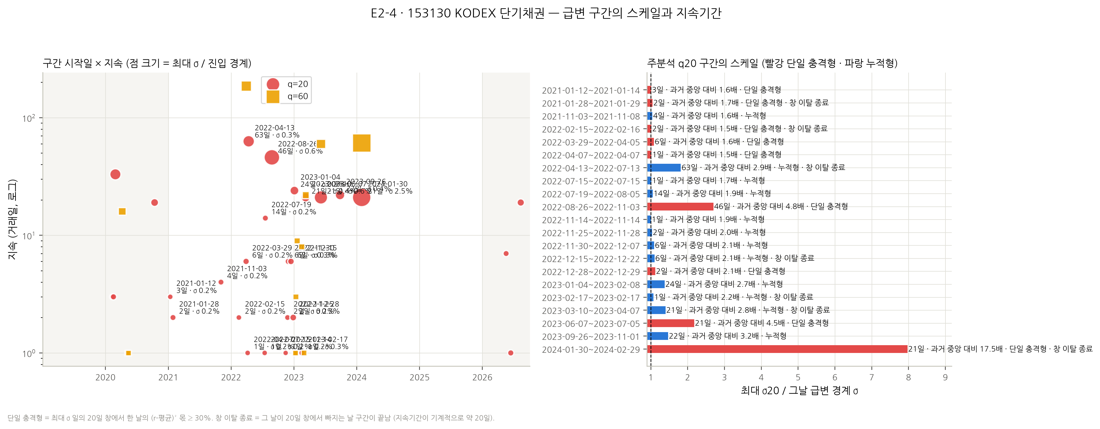

In [29]:
_cap = FG.e2_scale("153130", "4")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E2_4_153130_scale"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E2_4_153130_scale" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 6.4 바텀업 — 왜 잡혔나 (주분석 q20 구간)

In [30]:
# 최대 σ 일의 q 일 창에서 각 날의 분산 기여 (r−r̄)²/Σ, 진입일 수익률, 창 이탈 종료, 시장 공통성(10번 N_A·C1).
XP = X[(X["q"] == 20) & (X["period"] == "PRIMARY")]  # 주분석 q20 구간
display(XP[["interval_id", "start", "end", "duration", "shock_type", "top1_date", "top1_r", "top1_share", "top3", "window_exit_end", "entry_r", "entry_sigma_jump", "other_q_overlap_days", "max_N_A_q20", "C1_days"]].round(3))  # 바텀업 표

,interval_id,start,end,duration,shock_type,top1_date,top1_r,top1_share,top3,window_exit_end,entry_r,entry_sigma_jump,other_q_overlap_days,max_N_A_q20,C1_days
87,153130_q20_005,2021-01-12,2021-01-14,3,단일 충격형,2021-01-04,0.040,0.571,2021-01-04 +0.04% (57%); 2021-01-05 -0.01% (7%); 2021-01-07 +0.02% (6%),False,-0.005,0.002,0,2.0,0
88,153130_q20_006,2021-01-28,2021-01-29,2,단일 충격형,2021-01-04,0.040,0.522,2021-01-04 +0.04% (52%); 2021-01-29 +0.02% (11%); 2021-01-05 -0.01% (7%),True,-0.010,0.004,0,4.0,0
89,153130_q20_007,2021-11-03,2021-11-08,4,누적형,2021-10-28,-0.020,0.176,2021-10-28 -0.02% (18%); 2021-10-29 -0.02% (14%); 2021-11-03 +0.02% (14%),False,0.018,0.012,0,2.0,0
90,153130_q20_008,2022-02-15,2022-02-16,2,단일 충격형,2022-01-17,-0.025,0.367,2022-01-17 -0.02% (37%); 2022-01-27 +0.02% (12%); 2022-01-14 -0.01% (8%),True,-0.010,0.005,0,3.0,0
91,153130_q20_009,2022-03-29,2022-04-05,6,단일 충격형,2022-03-29,-0.035,0.500,2022-03-29 -0.03% (50%); 2022-03-08 +0.02% (14%); 2022-03-11 +0.01% (8%),False,-0.035,0.057,6,4.0,0
92,153130_q20_010,2022-04-07,2022-04-07,1,단일 충격형,2022-03-29,-0.035,0.542,2022-03-29 -0.03% (54%); 2022-03-11 +0.01% (10%); 2022-03-17 +0.01% (8%),False,0.010,0.003,1,2.0,0
93,153130_q20_011,2022-04-13,2022-07-13,63,누적형,2022-06-16,-0.051,0.294,2022-06-16 -0.05% (29%); 2022-06-15 -0.04% (22%); 2022-05-19 +0.02% (8%),True,-0.014,0.002,63,7.0,0
94,153130_q20_012,2022-07-15,2022-07-15,1,누적형,2022-07-15,-0.024,0.226,2022-07-15 -0.02% (23%); 2022-07-07 +0.02% (19%); 2022-07-01 -0.01% (9%),False,-0.024,0.015,1,4.0,0
95,153130_q20_013,2022-07-19,2022-08-05,14,누적형,2022-07-15,-0.024,0.286,2022-07-15 -0.02% (29%); 2022-07-11 -0.01% (15%); 2022-08-02 +0.02% (9%),False,0.020,0.011,14,5.0,0
96,153130_q20_014,2022-08-26,2022-11-03,46,단일 충격형,2022-09-23,-0.086,0.301,2022-09-23 -0.09% (30%); 2022-08-26 -0.08% (25%); 2022-09-14 +0.05% (11%),False,-0.079,0.163,46,9.0,2


확대 대상: ['153130_q20_011', '153130_q20_014', '153130_q20_020']


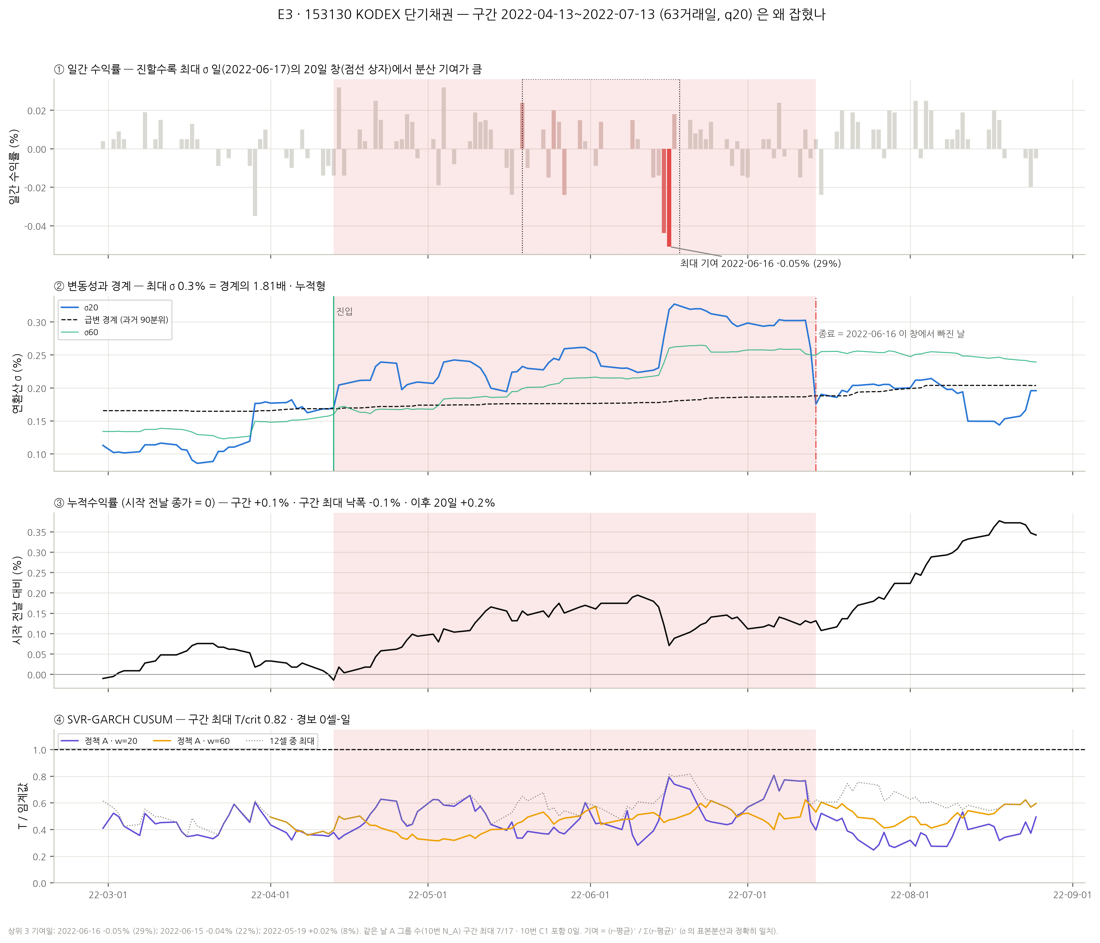

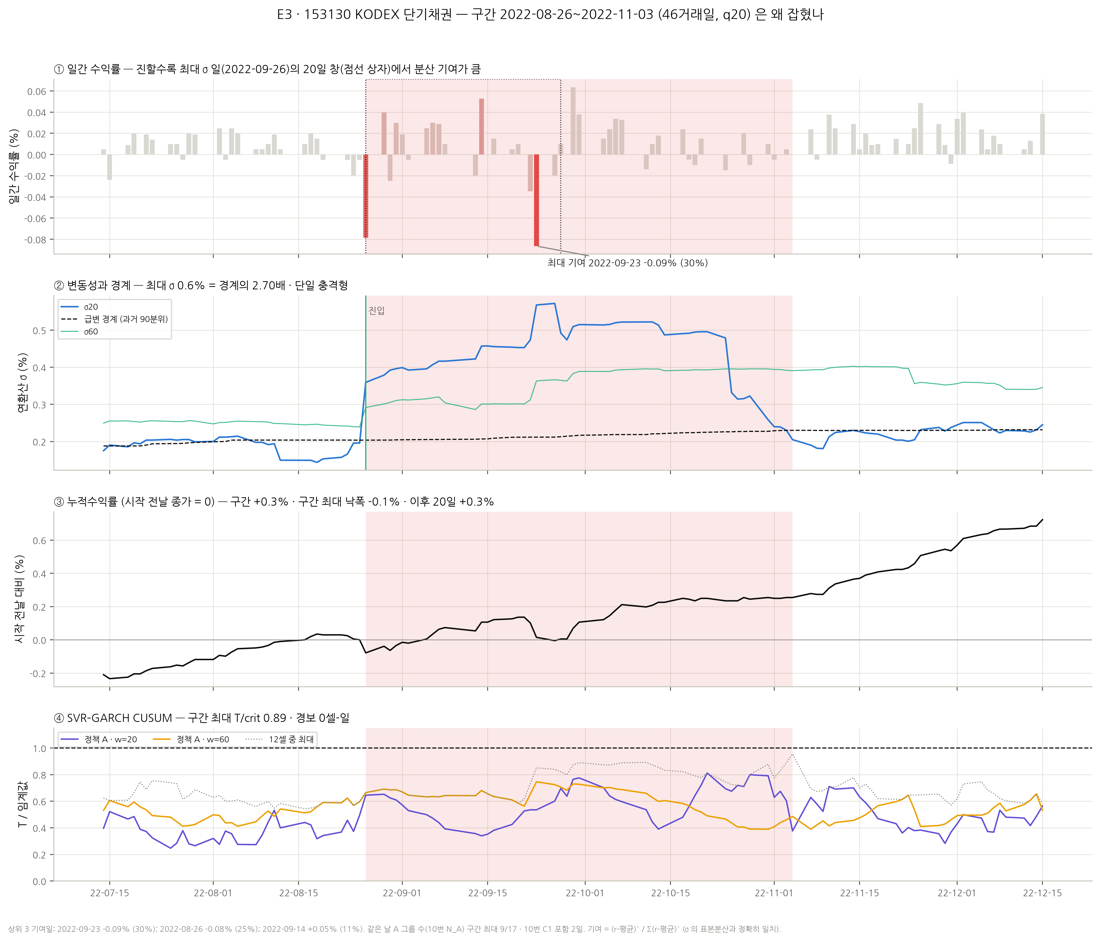

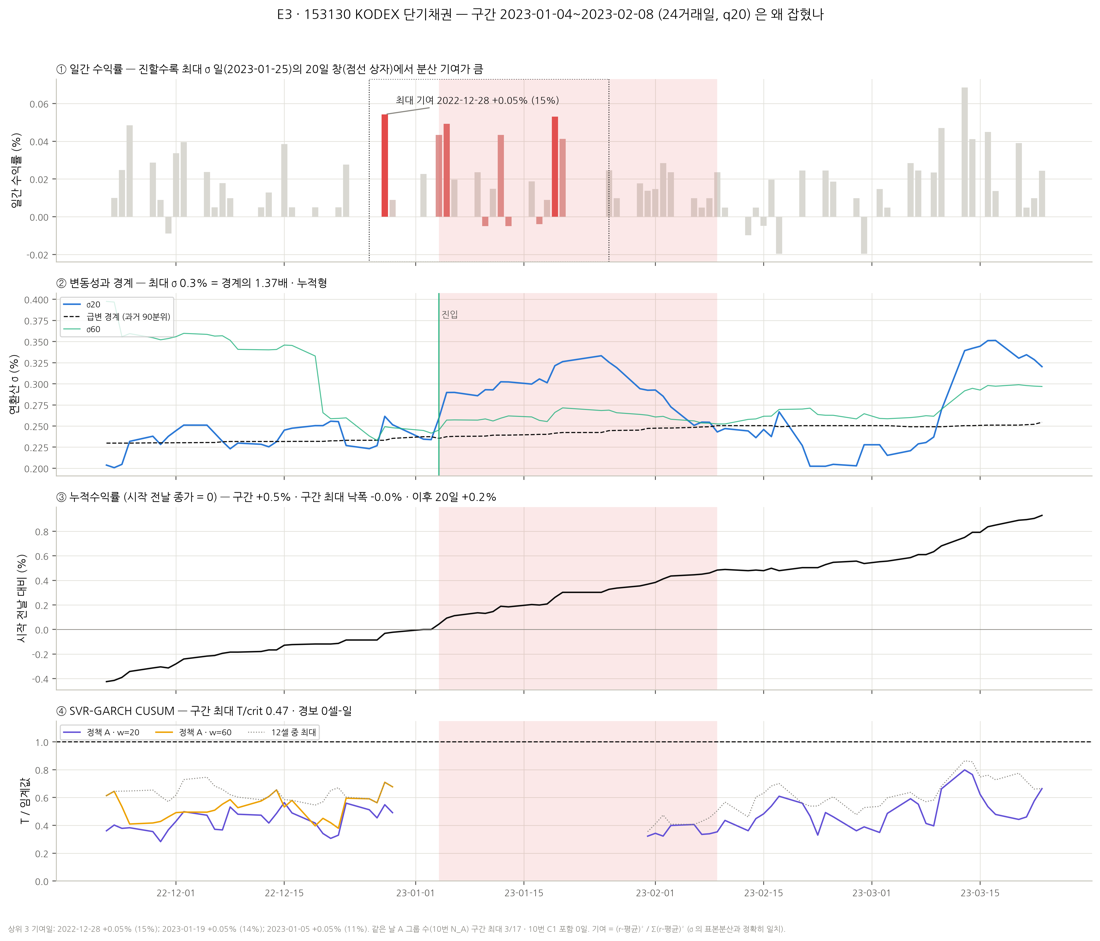

In [31]:
# 확대 대상: 주분석 q20 구간 중 지속 상위 3개 (동률은 시작일 순, 결과를 보고 바꾸지 않는 표시 규칙).
ZOOM = FG.zoom_targets("153130")  # 구간 ID 목록
print("확대 대상:", ZOOM)  # 대상 출력
for _iv in ZOOM:  # 구간마다
    CAP[f"E3_4_{_iv}"] = FG.e3_bottomup("153130", _iv, "4")  # 바텀업 4층 확대 그림
    display(Image(data=preview(FIGDIR / f"E3_4_{_iv}.png")))  # 미리보기

### 6.5 누적수익률

In [32]:
# 구간 수익률·최대 낙폭은 구간 시작 전날 종가 기준, 앞뒤 20거래일 수익률 (%).
display(XP[["interval_id", "start", "end", "ret_pre20_pct", "ret_interval_pct", "max_drawdown_pct", "ret_post20_pct"]].round(2))  # 누적수익률 표

,interval_id,start,end,ret_pre20_pct,ret_interval_pct,max_drawdown_pct,ret_post20_pct
87,153130_q20_005,2021-01-12,2021-01-14,0.07,0.01,-0.01,0.04
88,153130_q20_006,2021-01-28,2021-01-29,0.05,0.01,-0.01,0.05
89,153130_q20_007,2021-11-03,2021-11-08,-0.02,0.02,0.00,0.07
90,153130_q20_008,2022-02-15,2022-02-16,0.08,0.00,-0.01,0.13
91,153130_q20_009,2022-03-29,2022-04-05,0.08,-0.03,-0.03,0.06
92,153130_q20_010,2022-04-07,2022-04-07,-0.01,0.01,0.00,0.08
93,153130_q20_011,2022-04-13,2022-07-13,-0.05,0.13,-0.12,0.18
94,153130_q20_012,2022-07-15,2022-07-15,0.06,-0.02,-0.02,0.22
95,153130_q20_013,2022-07-19,2022-08-05,0.01,0.17,-0.00,0.06
96,153130_q20_014,2022-08-26,2022-11-03,0.16,0.25,-0.14,0.31


### 6.6 SVR–GARCH CUSUM

In [33]:
# 구간별 12셀(3정책 × 4창) 최대 T/crit 와 경보 셀-일 수, 2021–2025 급변일 vs 나머지 날 분포.
RC = [c for c in X.columns if c.startswith("maxR_")]  # 셀별 최대 비율 열
display(XP[["interval_id", "start", "end", "cusum_coverage_A20", "cusum_maxR_any", "cusum_alarm_days_any"] + RC].round(2))  # 구간별 CUSUM
IO = R["inside_outside"]  # 안팎 분포
display(IO[IO["ticker"] == "153130"].pivot_table(index=["policy", "w"], columns="side", values=["median_R", "max_R", "alarm_days"]).round(3))  # 셀별 안팎

,interval_id,start,end,cusum_coverage_A20,cusum_maxR_any,cusum_alarm_days_any,maxR_A_20,maxR_A_30,maxR_A_60,maxR_A_120,maxR_B_20,maxR_B_30,maxR_B_60,maxR_B_120,maxR_base_20,maxR_base_30,maxR_base_60,maxR_base_120
87,153130_q20_005,2021-01-12,2021-01-14,0.00,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
88,153130_q20_006,2021-01-28,2021-01-29,0.50,0.63,0,0.63,NaN,NaN,NaN,0.58,NaN,NaN,NaN,0.55,NaN,NaN,NaN
89,153130_q20_007,2021-11-03,2021-11-08,1.00,0.66,0,0.51,0.59,0.40,0.39,0.47,0.66,0.43,0.46,0.43,0.59,0.36,0.35
90,153130_q20_008,2022-02-15,2022-02-16,1.00,0.60,0,0.47,0.41,NaN,NaN,0.60,0.43,NaN,NaN,0.44,0.43,NaN,NaN
91,153130_q20_009,2022-03-29,2022-04-05,1.00,0.62,0,0.61,0.62,0.49,NaN,0.55,0.53,0.34,NaN,0.54,0.50,0.33,NaN
92,153130_q20_010,2022-04-07,2022-04-07,1.00,0.39,0,0.38,0.33,0.39,NaN,0.30,0.28,0.25,NaN,0.32,0.32,0.26,NaN
93,153130_q20_011,2022-04-13,2022-07-13,1.00,0.82,0,0.81,0.82,0.62,0.37,0.72,0.65,0.46,0.30,0.77,0.61,0.49,0.37
94,153130_q20_012,2022-07-15,2022-07-15,1.00,0.61,0,0.52,0.56,0.61,0.28,0.59,0.54,0.34,0.35,0.46,0.56,0.51,0.29
95,153130_q20_013,2022-07-19,2022-08-05,1.00,0.76,0,0.48,0.76,0.59,0.41,0.61,0.69,0.45,0.34,0.53,0.72,0.63,0.41
96,153130_q20_014,2022-08-26,2022-11-03,1.00,0.89,0,0.81,0.89,0.75,0.89,0.80,0.71,0.56,0.59,0.88,0.61,0.60,0.49


alarm_days          max_R         median_R        
side            A20 날 비 A20 날  A20 날 비 A20 날    A20 날 비 A20 날
policy w                                                     
A      20         0.0     0.0  0.890   0.915    0.520   0.425
       30         0.0     0.0  0.889   0.988    0.512   0.416
       60         0.0     0.0  0.786   0.800    0.494   0.439
       120        0.0    17.0  0.892   1.143    0.577   0.473
B      20         0.0     0.0  0.811   0.905    0.471   0.400
       30         0.0     0.0  0.714   0.850    0.438   0.387
       60         0.0     0.0  0.616   0.632    0.378   0.380
       120        0.0     0.0  0.594   0.829    0.356   0.382
base   20         0.0     0.0  0.878   0.982    0.473   0.406
       30         0.0     0.0  0.798   0.890    0.452   0.396
       60         0.0     0.0  0.808   0.943    0.425   0.407
       120        0.0    15.0  0.487   1.161    0.337   0.381

### 6.7 확장 — 앞 단계 ETF 와의 겹침

In [34]:
# 단계별 급변일 겹침 (주분석 q20): 069500 과 같은 날, 앞 단계 ETF 중 하나와 같은 날, 앞 단계와 겹치지 않는 단독 구간 수.
display(R["stage"][R["stage"]["order"] <= 4])  # 지금까지의 확장 단계

,order,ticker,stage,A20_days,days_with_069500,days_with_any_prev,intervals,intervals_alone_vs_prev
0,1,069500,S1 기준 (KOSPI200),95,95,0,7,7
1,2,229200,S1 코스닥 확장,121,47,47,13,9
2,3,148070,S2 국채10년 확장,261,0,35,19,13
3,4,153130,S3 단기채 확장,269,1,179,21,6


**해석 — 단기채권 (153130).**
- 주분석 q20 **21구간 269일**. σ 는 연 0.17–2.5% 다. **절대 변동성은 아주 작지만 자기 과거 분위로는 급변**이다.
- 가장 긴 구간은 2022-04-13~07-13 (63일)이고, 2022-08-26~11-03 (46일, 경계의 2.70배)이 이어진다. 2022 금리 국면이다.
- **주의**: 2024-01-30~02-29 구간은 최대 σ 2.49% 로 경계의 **7.97배**다. 이 값은 2024-01-31 의 +0.50% 하루(50%)가 만들었다. 이날은 T18(09) 에서 **원자료 이상치 후보(153130 2024-01-30·31)** 로 기록했다. 실제 급변으로 해석하지 않는다.
- **확장 관점**: 069500 과 같은 날은 1일뿐이다. 앞 단계와 겹친 날은 179일이고 대부분 148070(국채)과 겹친다. 21구간 중 6구간만 단독이다.
- CUSUM: W3 경보 32일(정책 A·base, w=120)은 **모두 급변일이 아닌 날**에 있다.

## 7. 133690 — 선정 · 급변 구간 · 스케일·지속 · 바텀업 · 누적수익률 · CUSUM

### 7.1 ETF 선정

**왜 이 ETF 인가 (미국 나스닥 확장).** TIGER 미국나스닥100 은 환노출 미국 기술주다. W3 의 S4 다. 국내 급변이 해외발인지 보는 비교축이다.

### 7.2 급변 구간 — 전체 연도 (2019–2026)

In [35]:
# 133690 의 q20·q60 급변 구간 전부 (전체 달력에서 한 번에 추출, 기간 지위는 시작일 기준 태그).
X = IV[IV["ticker"] == "133690"]  # 이 ETF 의 구간
display(X[["interval_id", "q", "period", "start", "end", "duration", "primary_days", "right_censored_data_end", "peak_date", "peak_sigma", "peak_U", "peak_over_boundary", "peak_over_past_median"]].round(3))  # 구간·스케일 표
display(R["summary"][R["summary"]["ticker"] == "133690"])  # 기간 지위별 요약

,interval_id,q,period,start,end,duration,primary_days,right_censored_data_end,peak_date,peak_sigma,peak_U,peak_over_boundary,peak_over_past_median
124,133690_q20_001,20,PILOT,2020-02-26,2020-04-21,39,0,False,2020-03-24,56.440,1.000,2.697,4.249
125,133690_q20_002,20,PILOT,2020-09-09,2020-10-06,17,0,False,2020-09-29,38.662,0.934,1.180,2.369
126,133690_q20_003,20,PRIMARY,2022-02-24,2022-03-25,20,20,False,2022-02-25,39.691,0.964,1.298,2.400
127,133690_q20_004,20,PRIMARY,2022-06-13,2022-06-17,5,5,False,2022-06-17,32.327,0.911,1.036,1.852
128,133690_q20_005,20,PRIMARY,2022-06-27,2022-06-27,1,1,False,2022-06-27,31.366,0.901,1.001,1.793
129,133690_q20_006,20,PRIMARY,2022-10-31,2022-11-14,11,11,False,2022-11-04,34.662,0.934,1.115,1.818
130,133690_q20_007,20,PRIMARY,2024-08-05,2024-09-02,20,20,False,2024-08-20,40.756,0.981,1.350,2.348
131,133690_q20_008,20,PRIMARY,2025-04-07,2025-05-12,23,23,False,2025-04-25,65.661,1.000,2.163,3.706
132,133690_q20_009,20,PARTIAL_NON_BLIND,2026-08-05,2026-08-05,1,0,False,2026-08-05,29.728,0.902,1.011,1.734
133,133690_q60_001,60,PILOT,2020-04-07,2020-05-27,33,0,False,2020-05-19,40.751,1.000,1.116,2.677


,ticker,q,period,n,days,primary_days,dur_median,dur_max,peak_sigma_max,single_shock,window_exit,cusum_alarm_intervals
21,133690,20,PILOT,2,56,0,28.0,39,56.440187,0,2,0
22,133690,20,PRIMARY,6,80,80,15.5,23,65.661257,3,2,0
23,133690,20,PARTIAL_NON_BLIND,1,1,0,1.0,1,29.727770,0,0,0
24,133690,60,PILOT,1,33,0,33.0,33,40.750991,0,0,0
25,133690,60,PRIMARY,8,79,79,2.0,60,40.800241,0,0,0


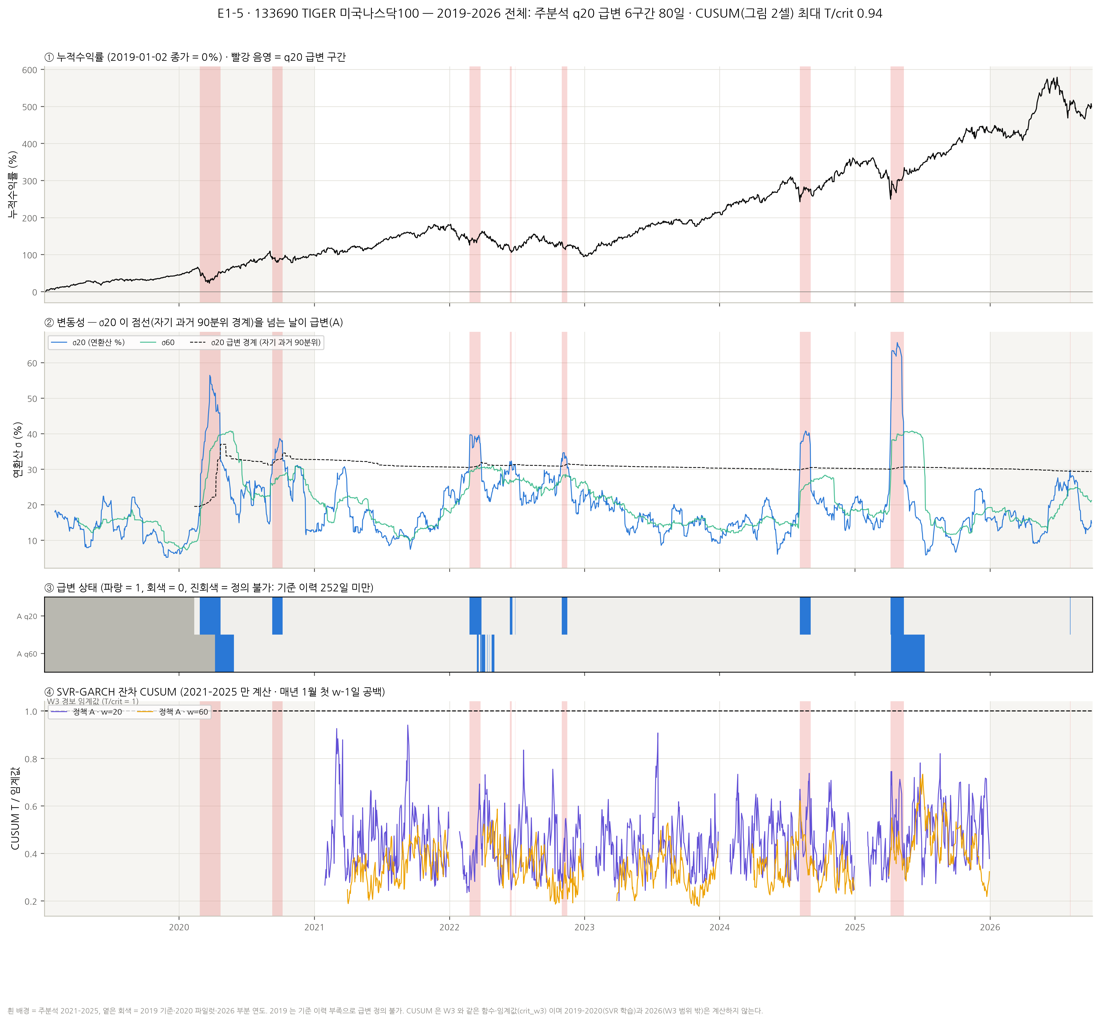

In [36]:
_cap = FG.e1_timeline("133690", "5")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E1_5_133690_timeline"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E1_5_133690_timeline" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 7.3 스케일·지속

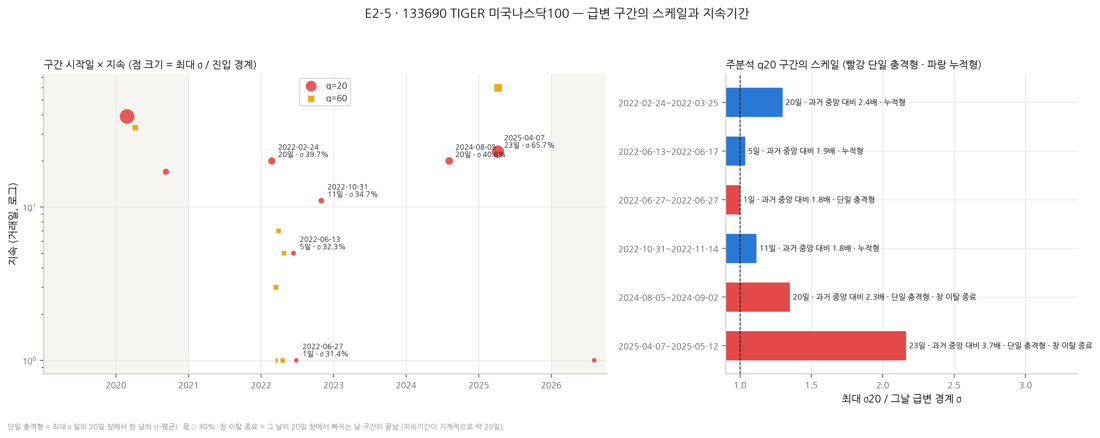

In [37]:
_cap = FG.e2_scale("133690", "5")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E2_5_133690_scale"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E2_5_133690_scale" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 7.4 바텀업 — 왜 잡혔나 (주분석 q20 구간)

In [38]:
# 최대 σ 일의 q 일 창에서 각 날의 분산 기여 (r−r̄)²/Σ, 진입일 수익률, 창 이탈 종료, 시장 공통성(10번 N_A·C1).
XP = X[(X["q"] == 20) & (X["period"] == "PRIMARY")]  # 주분석 q20 구간
display(XP[["interval_id", "start", "end", "duration", "shock_type", "top1_date", "top1_r", "top1_share", "top3", "window_exit_end", "entry_r", "entry_sigma_jump", "other_q_overlap_days", "max_N_A_q20", "C1_days"]].round(3))  # 바텀업 표

,interval_id,start,end,duration,shock_type,top1_date,top1_r,top1_share,top3,window_exit_end,entry_r,entry_sigma_jump,other_q_overlap_days,max_N_A_q20,C1_days
126,133690_q20_003,2022-02-24,2022-03-25,20,누적형,2022-02-25,5.096,0.231,2022-02-25 +5.10% (23%); 2022-02-24 -5.14% (21%); 2022-02-03 +4.31% (17%),False,-5.144,4.621,4,6.0,0
127,133690_q20_004,2022-06-13,2022-06-17,5,누적형,2022-06-13,-5.116,0.274,2022-06-13 -5.12% (27%); 2022-05-30 +3.59% (21%); 2022-05-19 -4.24% (18%),False,-5.116,3.477,0,5.0,0
128,133690_q20_005,2022-06-27,2022-06-27,1,단일 충격형,2022-06-13,-5.116,0.377,2022-06-13 -5.12% (38%); 2022-05-30 +3.59% (16%); 2022-06-17 -2.70% (11%),False,1.536,0.372,0,7.0,0
129,133690_q20_006,2022-10-31,2022-11-14,11,누적형,2022-10-31,3.999,0.205,2022-10-31 +4.00% (20%); 2022-10-24 +3.51% (16%); 2022-10-18 +3.47% (16%),False,3.999,2.981,0,6.0,0
130,133690_q20_007,2024-08-05,2024-09-02,20,단일 충격형,2024-08-05,-6.741,0.347,2024-08-05 -6.74% (35%); 2024-08-06 +5.07% (22%); 2024-08-02 -4.35% (14%),True,-6.741,8.472,0,10.0,20
131,133690_q20_008,2025-04-07,2025-05-12,23,단일 충격형,2025-04-10,10.080,0.327,2025-04-10 +10.08% (33%); 2025-04-07 -9.04% (24%); 2025-04-08 +6.76% (15%),True,-9.041,13.143,22,12.0,17


확대 대상: ['133690_q20_008', '133690_q20_003', '133690_q20_007']


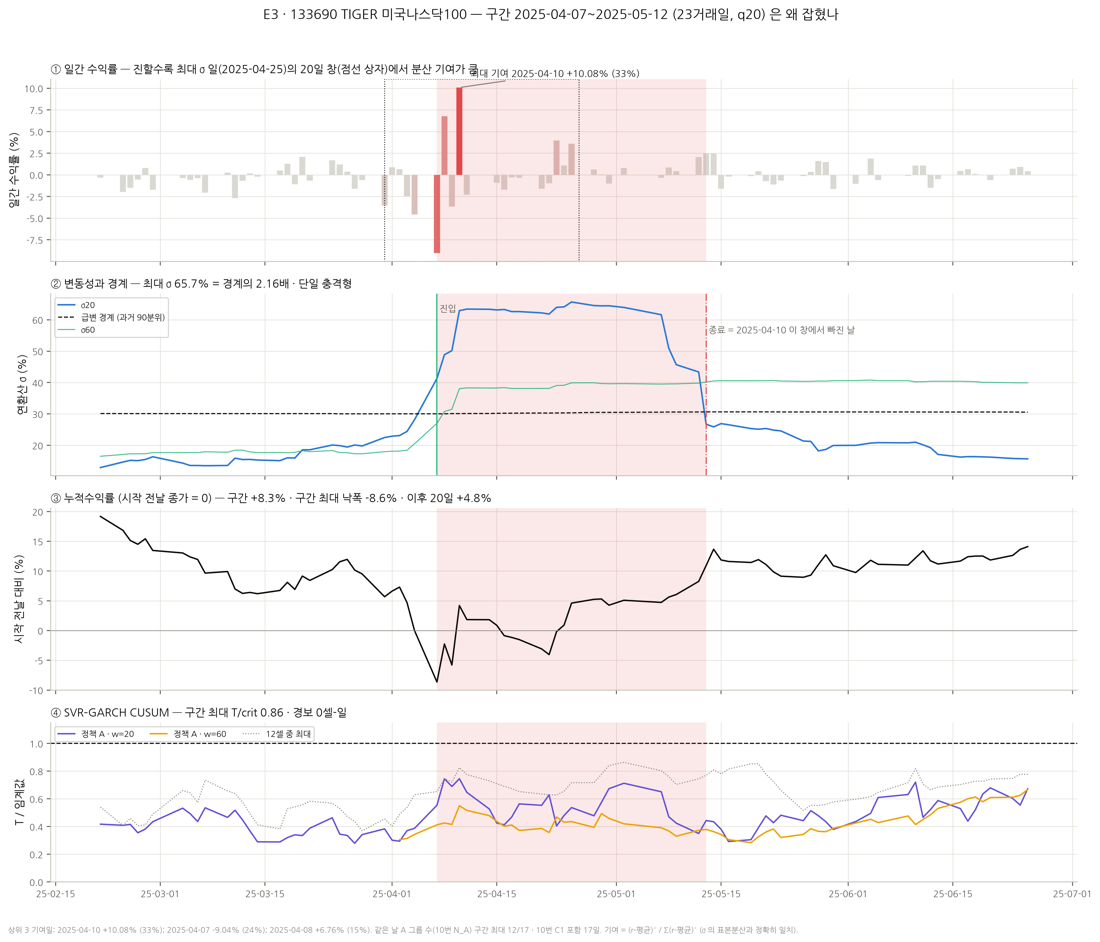

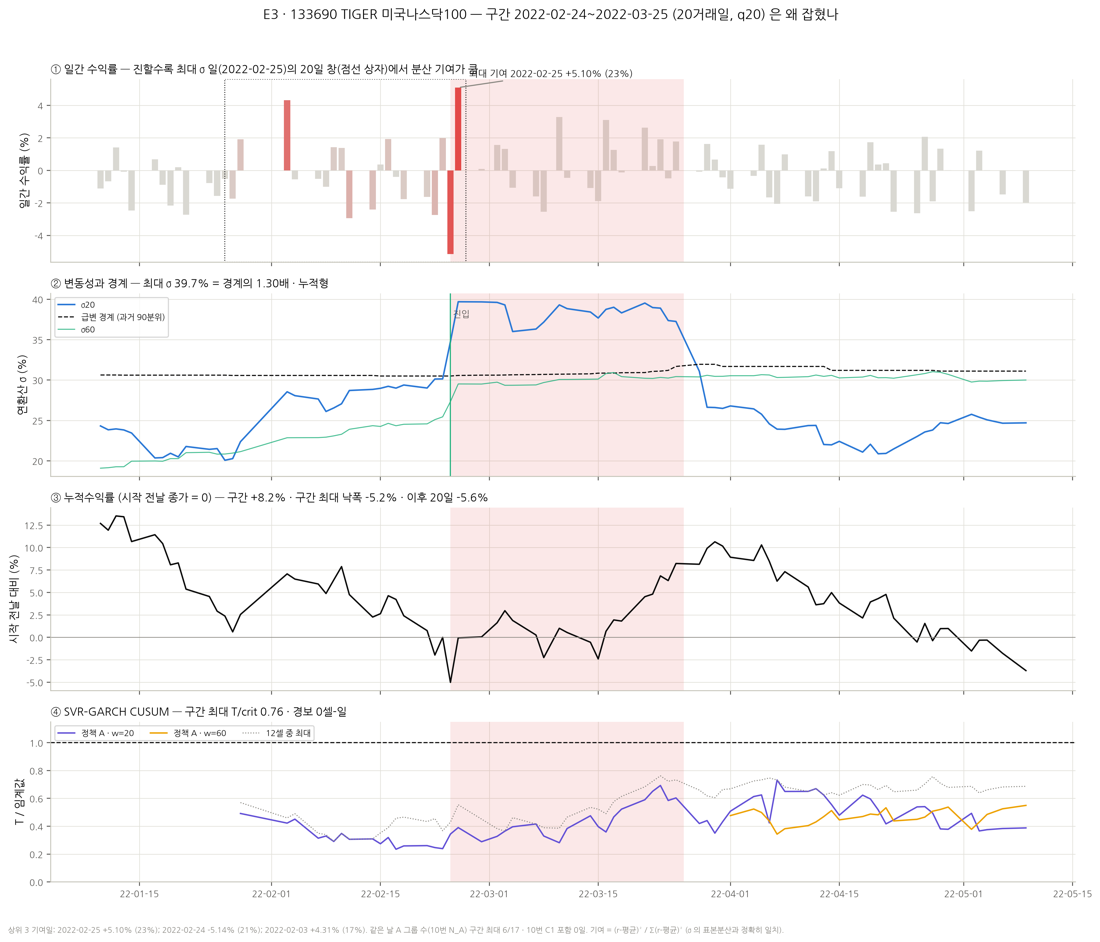

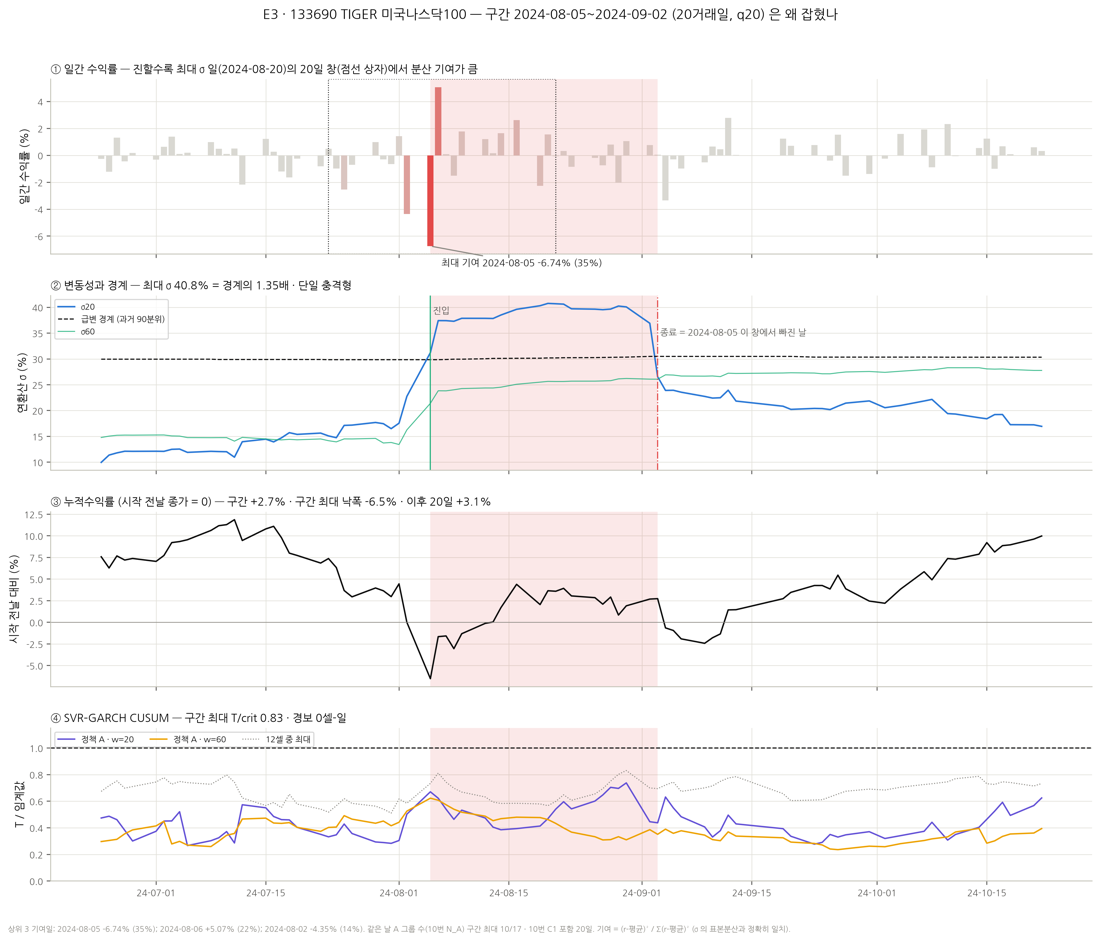

In [39]:
# 확대 대상: 주분석 q20 구간 중 지속 상위 3개 (동률은 시작일 순, 결과를 보고 바꾸지 않는 표시 규칙).
ZOOM = FG.zoom_targets("133690")  # 구간 ID 목록
print("확대 대상:", ZOOM)  # 대상 출력
for _iv in ZOOM:  # 구간마다
    CAP[f"E3_5_{_iv}"] = FG.e3_bottomup("133690", _iv, "5")  # 바텀업 4층 확대 그림
    display(Image(data=preview(FIGDIR / f"E3_5_{_iv}.png")))  # 미리보기

### 7.5 누적수익률

In [40]:
# 구간 수익률·최대 낙폭은 구간 시작 전날 종가 기준, 앞뒤 20거래일 수익률 (%).
display(XP[["interval_id", "start", "end", "ret_pre20_pct", "ret_interval_pct", "max_drawdown_pct", "ret_post20_pct"]].round(2))  # 누적수익률 표

,interval_id,start,end,ret_pre20_pct,ret_interval_pct,max_drawdown_pct,ret_post20_pct
126,133690_q20_003,2022-02-24,2022-03-25,-5.09,8.22,-5.22,-5.62
127,133690_q20_004,2022-06-13,2022-06-17,-1.56,-7.75,-7.75,8.43
128,133690_q20_005,2022-06-27,2022-06-27,2.50,1.55,0.00,4.46
129,133690_q20_006,2022-10-31,2022-11-14,-2.51,-1.02,-8.81,-2.99
130,133690_q20_007,2024-08-05,2024-09-02,-8.72,2.69,-6.52,3.08
131,133690_q20_008,2025-04-07,2025-05-12,-8.81,8.26,-8.64,4.75


### 7.6 SVR–GARCH CUSUM

In [41]:
# 구간별 12셀(3정책 × 4창) 최대 T/crit 와 경보 셀-일 수, 2021–2025 급변일 vs 나머지 날 분포.
RC = [c for c in X.columns if c.startswith("maxR_")]  # 셀별 최대 비율 열
display(XP[["interval_id", "start", "end", "cusum_coverage_A20", "cusum_maxR_any", "cusum_alarm_days_any"] + RC].round(2))  # 구간별 CUSUM
IO = R["inside_outside"]  # 안팎 분포
display(IO[IO["ticker"] == "133690"].pivot_table(index=["policy", "w"], columns="side", values=["median_R", "max_R", "alarm_days"]).round(3))  # 셀별 안팎

,interval_id,start,end,cusum_coverage_A20,cusum_maxR_any,cusum_alarm_days_any,maxR_A_20,maxR_A_30,maxR_A_60,maxR_A_120,maxR_B_20,maxR_B_30,maxR_B_60,maxR_B_120,maxR_base_20,maxR_base_30,maxR_base_60,maxR_base_120
126,133690_q20_003,2022-02-24,2022-03-25,1.0,0.76,0,0.69,0.58,NaN,NaN,0.67,0.51,NaN,NaN,0.76,0.62,NaN,NaN
127,133690_q20_004,2022-06-13,2022-06-17,1.0,0.52,0,0.49,0.50,0.52,NaN,0.43,0.36,0.39,NaN,0.45,0.41,0.44,NaN
128,133690_q20_005,2022-06-27,2022-06-27,1.0,0.50,0,0.50,0.33,0.30,NaN,0.41,0.28,0.24,NaN,0.36,0.22,0.35,NaN
129,133690_q20_006,2022-10-31,2022-11-14,1.0,0.65,0,0.55,0.45,0.36,0.32,0.47,0.65,0.37,0.23,0.44,0.59,0.35,0.35
130,133690_q20_007,2024-08-05,2024-09-02,1.0,0.83,0,0.74,0.66,0.62,0.53,0.79,0.66,0.68,0.51,0.83,0.77,0.67,0.59
131,133690_q20_008,2025-04-07,2025-05-12,1.0,0.86,0,0.75,0.76,0.55,NaN,0.83,0.77,0.77,NaN,0.86,0.82,0.77,NaN


alarm_days          max_R         median_R        
side            A20 날 비 A20 날  A20 날 비 A20 날    A20 날 비 A20 날
policy w                                                     
A      20         0.0     0.0  0.745   0.941    0.474   0.433
       30         0.0     0.0  0.760   0.787    0.416   0.406
       60         0.0     0.0  0.623   0.734    0.411   0.348
       120        0.0     0.0  0.529   0.785    0.421   0.286
B      20         0.0     3.0  0.827   1.077    0.501   0.459
       30         0.0     0.0  0.769   1.000    0.463   0.438
       60         0.0     0.0  0.767   0.787    0.496   0.388
       120        0.0     0.0  0.515   0.776    0.345   0.329
base   20         0.0     1.0  0.864   1.063    0.549   0.475
       30         0.0     0.0  0.815   0.997    0.503   0.456
       60         0.0     0.0  0.766   0.840    0.527   0.412
       120        0.0     0.0  0.586   0.733    0.495   0.445

### 7.7 확장 — 앞 단계 ETF 와의 겹침

In [42]:
# 단계별 급변일 겹침 (주분석 q20): 069500 과 같은 날, 앞 단계 ETF 중 하나와 같은 날, 앞 단계와 겹치지 않는 단독 구간 수.
display(R["stage"][R["stage"]["order"] <= 5])  # 지금까지의 확장 단계

,order,ticker,stage,A20_days,days_with_069500,days_with_any_prev,intervals,intervals_alone_vs_prev
0,1,069500,S1 기준 (KOSPI200),95,95,0,7,7
1,2,229200,S1 코스닥 확장,121,47,47,13,9
2,3,148070,S2 국채10년 확장,261,0,35,19,13
3,4,153130,S3 단기채 확장,269,1,179,21,6
4,5,133690,S4 미국 나스닥 확장,80,42,75,6,0


**해석 — 미국 나스닥100 (133690).**
- 주분석 q20 **6구간 80일**. 2022 년 4구간과 2024-08, 2025-04 다.
- 2025-04-07~05-12 (23일) 이 가장 크다. 최대 σ 65.7% 로 경계의 2.16배이고, 2025-04-10 +10.08% 의 날이 창 분산의 33% 를 만들었다.
- 2024-08-05~09-02 (20일) 은 069500·229200 과 날짜가 같다. 단일 충격(08-05 −6.74%)의 창 이탈 종료다.
- **확장 관점**: 6구간 모두 앞 단계 ETF 의 급변일과 겹친다 (단독 0). 069500 과 같은 날은 42일이다. 2024-08·2025-04 는 국내 급변과 해외 급변이 같은 날 일어난 다자산 사건이다.
- CUSUM: W3 경보 4일(정책 B·w20 3일, base·w20 1일)은 모두 급변일이 아닌 날이다.

## 8. 261220 — 선정 · 급변 구간 · 스케일·지속 · 바텀업 · 누적수익률 · CUSUM

### 8.1 ETF 선정

**왜 이 ETF 인가 (원유 확장).** KODEX WTI원유선물(H)은 원자재 위험이다. W3 의 S5 다. 원유 고유의 급변과 다자산 동시 급변을 가른다.

### 8.2 급변 구간 — 전체 연도 (2019–2026)

In [43]:
# 261220 의 q20·q60 급변 구간 전부 (전체 달력에서 한 번에 추출, 기간 지위는 시작일 기준 태그).
X = IV[IV["ticker"] == "261220"]  # 이 ETF 의 구간
display(X[["interval_id", "q", "period", "start", "end", "duration", "primary_days", "right_censored_data_end", "peak_date", "peak_sigma", "peak_U", "peak_over_boundary", "peak_over_past_median"]].round(3))  # 구간·스케일 표
display(R["summary"][R["summary"]["ticker"] == "261220"])  # 기간 지위별 요약

,interval_id,q,period,start,end,duration,primary_days,right_censored_data_end,peak_date,peak_sigma,peak_U,peak_over_boundary,peak_over_past_median
142,261220_q20_001,20,PILOT,2020-02-28,2020-05-22,57,0,False,2020-05-06,195.470,1.000,1.434,6.761
143,261220_q20_002,20,PRIMARY,2022-03-07,2022-04-06,22,22,False,2022-03-29,99.758,0.929,1.551,3.188
144,261220_q20_003,20,PRIMARY,2025-04-10,2025-05-07,17,17,False,2025-04-28,57.942,0.932,1.143,1.803
145,261220_q20_004,20,PRIMARY,2025-06-24,2025-07-21,20,20,False,2025-06-24,67.355,0.949,1.317,2.087
146,261220_q20_005,20,PARTIAL_NON_BLIND,2026-03-09,2026-06-01,58,0,False,2026-03-30,132.820,0.973,2.493,4.203
147,261220_q20_006,20,PARTIAL_NON_BLIND,2026-07-27,2026-08-21,19,0,False,2026-08-11,69.307,0.934,1.190,2.147
148,261220_q60_001,60,PILOT,2020-04-07,2020-06-10,43,0,False,2020-06-03,157.843,1.000,1.333,5.323
149,261220_q60_002,60,PILOT,2020-06-12,2020-06-15,2,0,False,2020-06-15,140.008,0.906,1.000,4.663
150,261220_q60_003,60,PARTIAL_NON_BLIND,2026-03-09,2026-06-30,78,0,False,2026-05-28,99.355,0.954,1.534,2.964


,ticker,q,period,n,days,primary_days,dur_median,dur_max,peak_sigma_max,single_shock,window_exit,cusum_alarm_intervals
26,261220,20,PILOT,1,57,0,57.0,57,195.470245,1,1,0
27,261220,20,PRIMARY,3,59,59,20.0,22,99.757875,2,2,0
28,261220,20,PARTIAL_NON_BLIND,2,77,0,38.5,58,132.820176,1,0,0
29,261220,60,PILOT,2,45,0,22.5,43,157.842954,0,0,0
30,261220,60,PARTIAL_NON_BLIND,1,78,0,78.0,78,99.354509,0,0,0


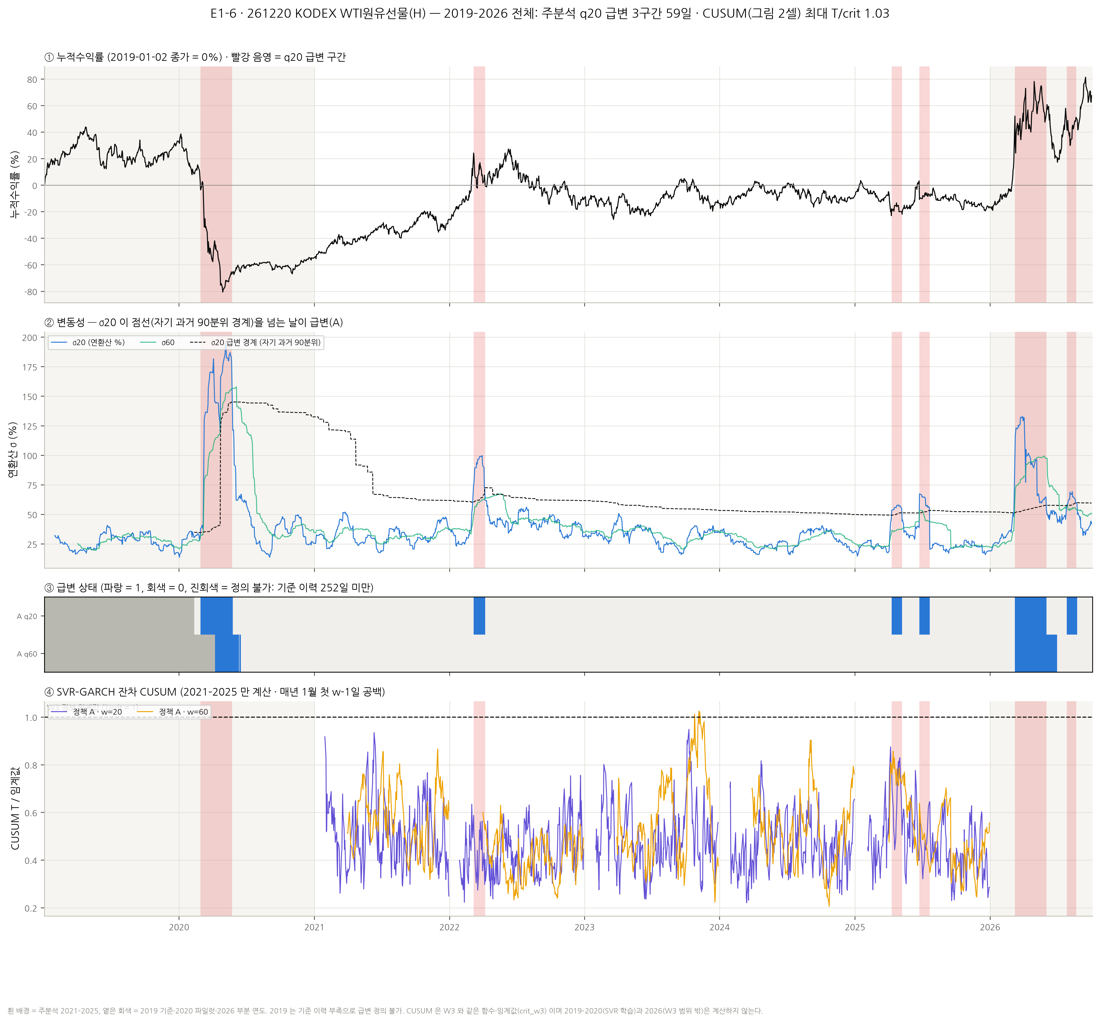

In [44]:
_cap = FG.e1_timeline("261220", "6")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E1_6_261220_timeline"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E1_6_261220_timeline" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 8.3 스케일·지속

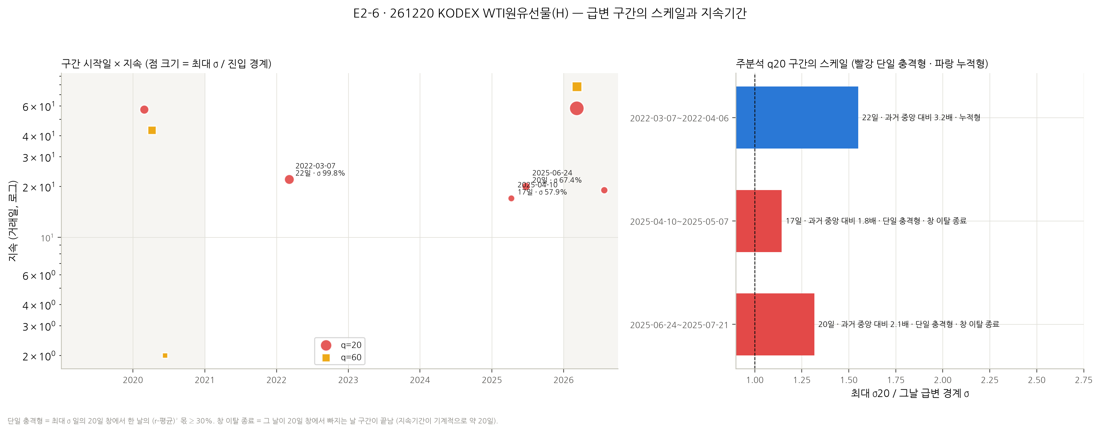

In [45]:
_cap = FG.e2_scale("261220", "6")  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["E2_6_261220_scale"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("E2_6_261220_scale" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

### 8.4 바텀업 — 왜 잡혔나 (주분석 q20 구간)

In [46]:
# 최대 σ 일의 q 일 창에서 각 날의 분산 기여 (r−r̄)²/Σ, 진입일 수익률, 창 이탈 종료, 시장 공통성(10번 N_A·C1).
XP = X[(X["q"] == 20) & (X["period"] == "PRIMARY")]  # 주분석 q20 구간
display(XP[["interval_id", "start", "end", "duration", "shock_type", "top1_date", "top1_r", "top1_share", "top3", "window_exit_end", "entry_r", "entry_sigma_jump", "other_q_overlap_days", "max_N_A_q20", "C1_days"]].round(3))  # 바텀업 표

,interval_id,start,end,duration,shock_type,top1_date,top1_r,top1_share,top3,window_exit_end,entry_r,entry_sigma_jump,other_q_overlap_days,max_N_A_q20,C1_days
143,261220_q20_002,2022-03-07,2022-04-06,22,누적형,2022-03-07,14.795,0.266,2022-03-07 +14.79% (27%); 2022-03-10 -11.60% (20%); 2022-03-02 +10.78% (14%),False,14.795,17.467,0,6.0,0
144,261220_q20_003,2025-04-10,2025-05-07,17,단일 충격형,2025-04-07,-9.556,0.330,2025-04-07 -9.56% (33%); 2025-04-10 +6.53% (19%); 2025-04-09 -5.58% (11%),True,6.527,5.923,0,12.0,17
145,261220_q20_004,2025-06-24,2025-07-21,20,단일 충격형,2025-06-24,-14.475,0.648,2025-06-24 -14.47% (65%); 2025-06-13 +7.58% (15%); 2025-05-30 -3.39% (4%),True,-14.475,28.455,0,2.0,0


확대 대상: ['261220_q20_002', '261220_q20_004', '261220_q20_003']


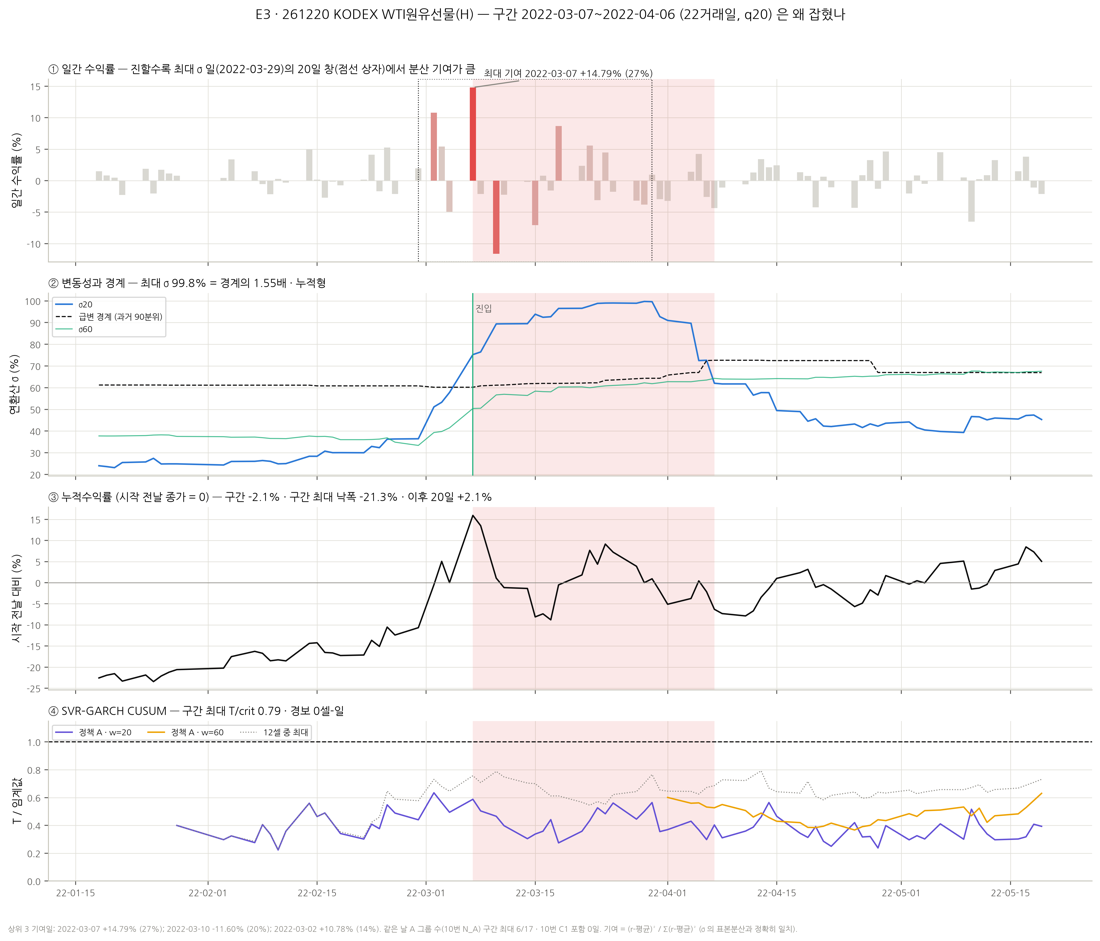

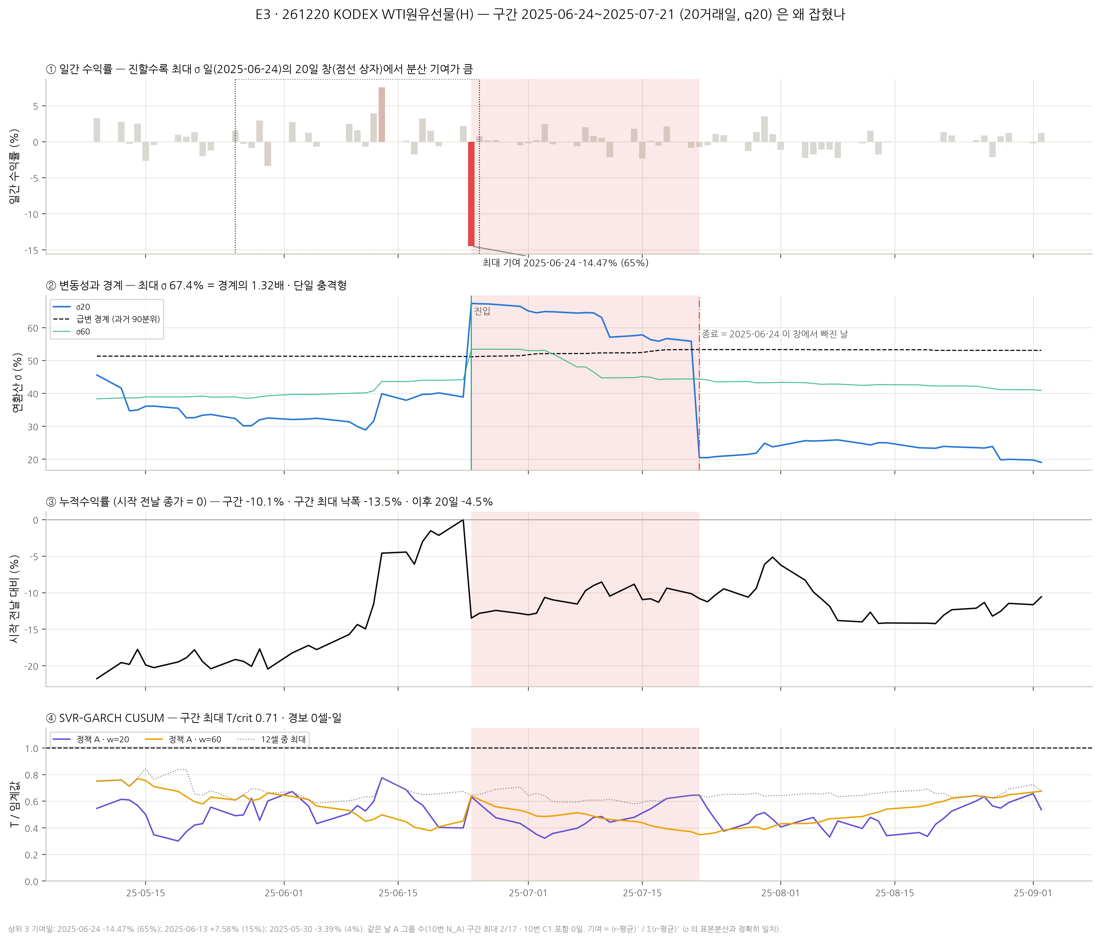

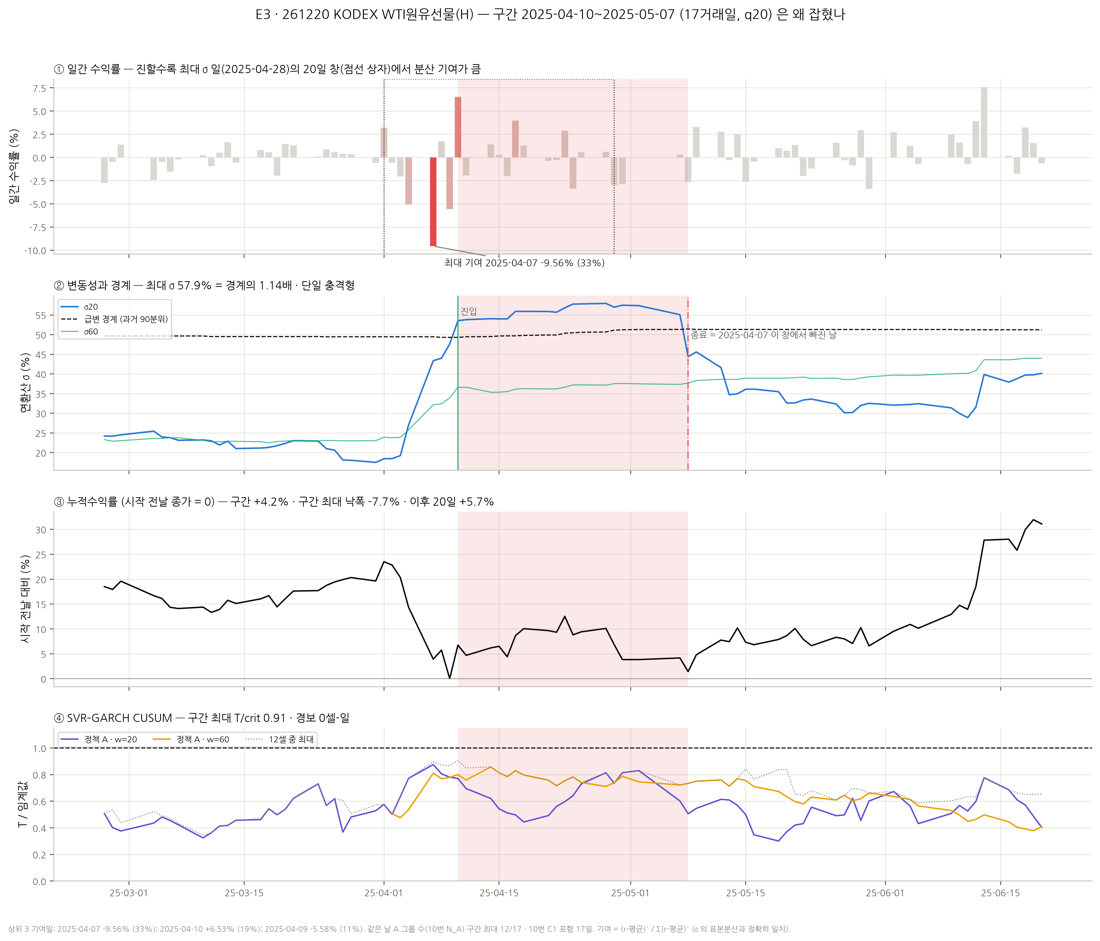

In [47]:
# 확대 대상: 주분석 q20 구간 중 지속 상위 3개 (동률은 시작일 순, 결과를 보고 바꾸지 않는 표시 규칙).
ZOOM = FG.zoom_targets("261220")  # 구간 ID 목록
print("확대 대상:", ZOOM)  # 대상 출력
for _iv in ZOOM:  # 구간마다
    CAP[f"E3_6_{_iv}"] = FG.e3_bottomup("261220", _iv, "6")  # 바텀업 4층 확대 그림
    display(Image(data=preview(FIGDIR / f"E3_6_{_iv}.png")))  # 미리보기

### 8.5 누적수익률

In [48]:
# 구간 수익률·최대 낙폭은 구간 시작 전날 종가 기준, 앞뒤 20거래일 수익률 (%).
display(XP[["interval_id", "start", "end", "ret_pre20_pct", "ret_interval_pct", "max_drawdown_pct", "ret_post20_pct"]].round(2))  # 누적수익률 표

,interval_id,start,end,ret_pre20_pct,ret_interval_pct,max_drawdown_pct,ret_post20_pct
143,261220_q20_002,2022-03-07,2022-04-06,25.38,-2.15,-21.34,2.14
144,261220_q20_003,2025-04-10,2025-05-07,-12.20,4.16,-7.72,5.74
145,261220_q20_004,2025-06-24,2025-07-21,24.14,-10.13,-13.48,-4.50


### 8.6 SVR–GARCH CUSUM

In [49]:
# 구간별 12셀(3정책 × 4창) 최대 T/crit 와 경보 셀-일 수, 2021–2025 급변일 vs 나머지 날 분포.
RC = [c for c in X.columns if c.startswith("maxR_")]  # 셀별 최대 비율 열
display(XP[["interval_id", "start", "end", "cusum_coverage_A20", "cusum_maxR_any", "cusum_alarm_days_any"] + RC].round(2))  # 구간별 CUSUM
IO = R["inside_outside"]  # 안팎 분포
display(IO[IO["ticker"] == "261220"].pivot_table(index=["policy", "w"], columns="side", values=["median_R", "max_R", "alarm_days"]).round(3))  # 셀별 안팎

,interval_id,start,end,cusum_coverage_A20,cusum_maxR_any,cusum_alarm_days_any,maxR_A_20,maxR_A_30,maxR_A_60,maxR_A_120,maxR_B_20,maxR_B_30,maxR_B_60,maxR_B_120,maxR_base_20,maxR_base_30,maxR_base_60,maxR_base_120
143,261220_q20_002,2022-03-07,2022-04-06,1.0,0.79,0,0.59,0.73,0.60,NaN,0.62,0.63,0.41,NaN,0.77,0.79,0.55,NaN
144,261220_q20_003,2025-04-10,2025-05-07,1.0,0.91,0,0.83,0.91,0.86,NaN,0.77,0.69,0.60,NaN,0.74,0.74,0.64,NaN
145,261220_q20_004,2025-06-24,2025-07-21,1.0,0.71,0,0.64,0.64,0.64,0.61,0.58,0.53,0.71,0.62,0.56,0.50,0.52,0.32


alarm_days          max_R         median_R        
side            A20 날 비 A20 날  A20 날 비 A20 날    A20 날 비 A20 날
policy w                                                     
A      20         0.0     0.0  0.830   0.949    0.492   0.456
       30         0.0     0.0  0.906   0.989    0.496   0.471
       60         0.0     4.0  0.857   1.026    0.585   0.496
       120        0.0     5.0  0.611   1.128    0.565   0.570
B      20         0.0     0.0  0.767   0.929    0.488   0.433
       30         0.0     0.0  0.690   0.928    0.443   0.426
       60         0.0     0.0  0.706   0.872    0.412   0.414
       120        0.0     0.0  0.615   0.825    0.603   0.481
base   20         0.0     0.0  0.766   0.885    0.515   0.443
       30         0.0     0.0  0.788   0.882    0.468   0.433
       60         0.0     0.0  0.639   0.857    0.499   0.438
       120        0.0     0.0  0.321   0.852    0.285   0.447

### 8.7 확장 — 앞 단계 ETF 와의 겹침

In [50]:
# 단계별 급변일 겹침 (주분석 q20): 069500 과 같은 날, 앞 단계 ETF 중 하나와 같은 날, 앞 단계와 겹치지 않는 단독 구간 수.
display(R["stage"][R["stage"]["order"] <= 6])  # 지금까지의 확장 단계

,order,ticker,stage,A20_days,days_with_069500,days_with_any_prev,intervals,intervals_alone_vs_prev
0,1,069500,S1 기준 (KOSPI200),95,95,0,7,7
1,2,229200,S1 코스닥 확장,121,47,47,13,9
2,3,148070,S2 국채10년 확장,261,0,35,19,13
3,4,153130,S3 단기채 확장,269,1,179,21,6
4,5,133690,S4 미국 나스닥 확장,80,42,75,6,0
5,6,261220,S5 원유 확장,59,17,39,3,1


**해석 — WTI원유 (261220).**
- 주분석 q20 **3구간 59일**. q60 주분석 구간은 없다.
- 2022-03-07~04-06 (22일) 은 최대 σ 99.8%, 구간 최대 낙폭 −21.3% 의 누적형이다.
- 2025-06-24~07-21 (20일) 은 하루(06-24, −14.47%)가 65% 를 만든 단일 충격이고, 창 이탈로 끝났다. 같은 날 A 그룹 수는 최대 2 로 **원유 고유 급변**이다.
- 2025-04-10~05-07 (17일) 은 다자산 급변(N_A 12)에 원유가 함께한 경우다.
- CUSUM: W3 경보 9일(정책 A·w60 4일, w120 5일)은 모두 급변일이 아닌 날이다.

## 9. 6종 종합 — 확장 지도

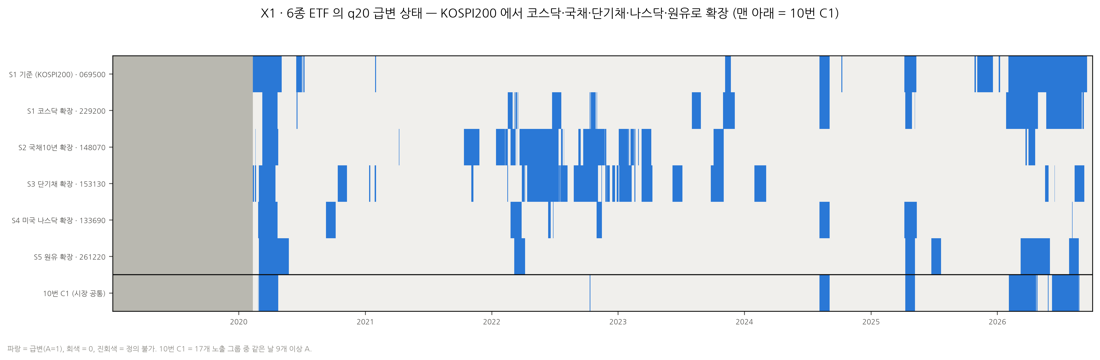

In [51]:
_cap = FG.x1_stack()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["X1_six_etf_stack"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("X1_six_etf_stack" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

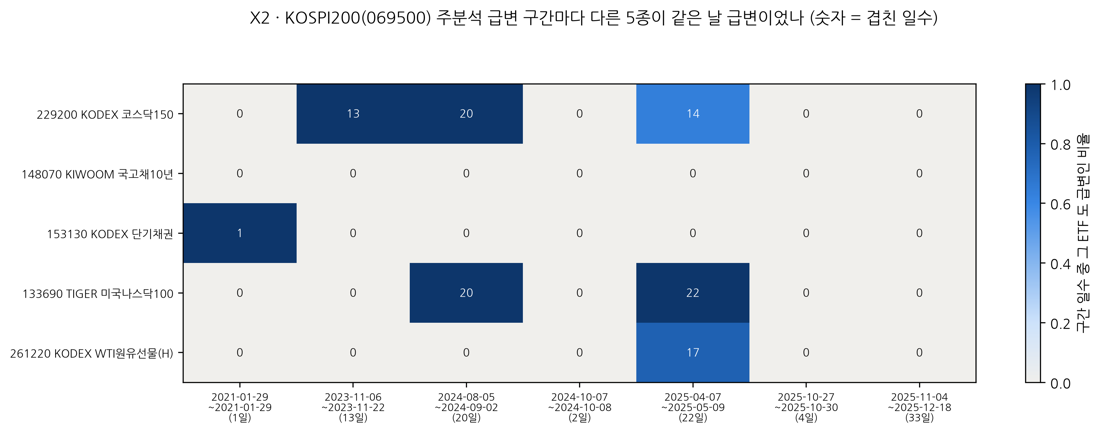

In [52]:
_cap = FG.x2_participation()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["X2_kospi200_participation"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("X2_kospi200_participation" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

In [53]:
# 확장 단계 표 (주분석 q20) 와 KOSPI200 구간별 참여 일수.
display(R["stage"])  # 단계별 겹침
display(R["k200_participation"])  # 069500 구간 × 다른 5종

,order,ticker,stage,A20_days,days_with_069500,days_with_any_prev,intervals,intervals_alone_vs_prev
0,1,069500,S1 기준 (KOSPI200),95,95,0,7,7
1,2,229200,S1 코스닥 확장,121,47,47,13,9
2,3,148070,S2 국채10년 확장,261,0,35,19,13
3,4,153130,S3 단기채 확장,269,1,179,21,6
4,5,133690,S4 미국 나스닥 확장,80,42,75,6,0
5,6,261220,S5 원유 확장,59,17,39,3,1


,interval_id,start,end,duration,229200,148070,153130,133690,261220
0,069500_q20_005,2021-01-29,2021-01-29,1,0,0,1,0,0
1,069500_q20_006,2023-11-06,2023-11-22,13,13,0,0,0,0
2,069500_q20_007,2024-08-05,2024-09-02,20,20,0,0,20,0
3,069500_q20_008,2024-10-07,2024-10-08,2,0,0,0,0,0
4,069500_q20_009,2025-04-07,2025-05-09,22,14,0,0,22,17
5,069500_q20_010,2025-10-27,2025-10-30,4,0,0,0,0,0
6,069500_q20_011,2025-11-04,2025-12-18,33,0,0,0,0,0


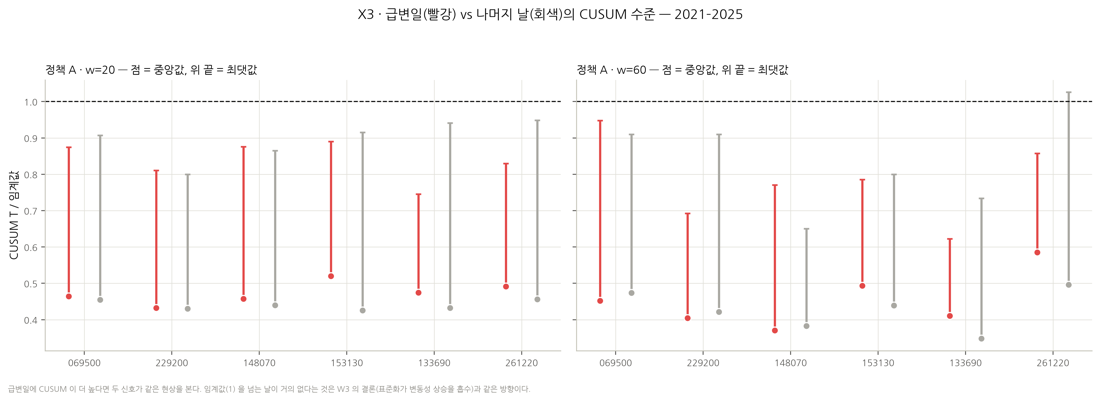

In [54]:
_cap = FG.x3_cusum_io()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["X3_cusum_inside_outside"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("X3_cusum_inside_outside" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

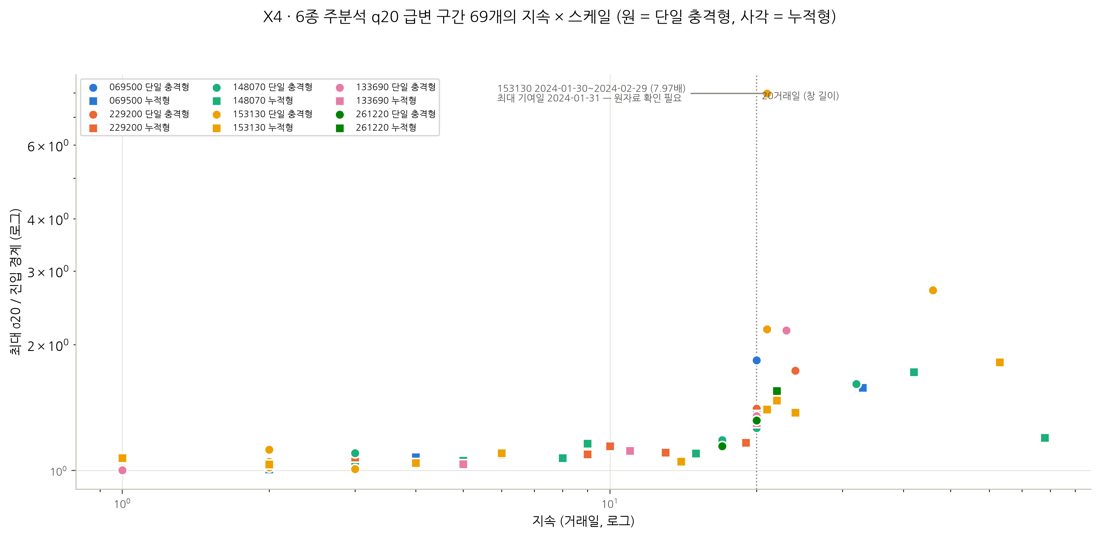

In [55]:
_cap = FG.x4_all()  # 결과로 그림을 다시 그리고 캡션 수치를 받는다
CAP["X4_all_intervals"] = _cap  # 캡션 수치 보관
display(Image(data=preview(FIGDIR / ("X4_all_intervals" + ".png"))))  # 저장된 PNG(320dpi)의 축소 미리보기

**해석 (X1–X4).**
- **확장 지도**: 국내 주식(069500·229200)의 급변은 2023-11, 2024-08, 2025-04 에 함께 온다. 국채·단기채(148070·153130)의 급변은 2022 금리 국면에 길게 몰려 있고 국내 주식과 거의 겹치지 않는다 (069500 과 같은 날: 148070 0일, 153130 1일).
- 나스닥(133690)의 6구간은 모두 앞 단계 ETF 와 겹친다. 원유(261220)는 2025-06 의 고유 급변 하나를 더한다.
- **KOSPI200 구간의 성격 (X2)**: 2024-08 은 코스닥·나스닥이 20일 모두 함께했다. 2025-04 는 나스닥 22일, 원유 17일, 코스닥 14일이 함께한 다자산 급변이다. 2023-11 은 코스닥만, 2025-10~12 는 069500 단독이다.
- **지속기간의 기계적 성분 (X4)**: 주분석 q20 구간 69개 중 25개가 단일 충격형이다. 24개는 최대 기여일이 창에서 빠지는 날 끝났다. 20거래일 근처에 몰린 지속기간은 상당 부분 **창 길이의 흔적**이다.
- **CUSUM (X3)**: 6종 × 12셀 어디에서도 **급변일에 경보가 0일**이다. W3 의 경보(153130 32일·261220 9일·133690 4일)는 모두 급변이 아닌 날에 있다. 정책 A 의 급변일 T/crit 중앙값도 나머지 날과 비슷한 범위다 (4개 창 × 6종: 0.37–0.59 대 0.29–0.57). 관측 변동성의 급등과 SVR 표준화 잔차의 분산 변화는 다른 시점에 나타난다.

## 10. 결론 · 한계 · 다음 단계

**결론**
1. ETF 단위 급변 구간은 자산마다 시기가 다르다. 국내 주식은 2023-11·2024-08·2025-04(·2025-11 국내 고유), 국채·단기채는 2022 금리 국면, 원유는 2022-03·2025-06 이다.
2. 시장 공통 급변(10번 C1)은 이 개별 구간들이 같은 날 겹친 부분이다. 2024-08 과 2025-04 가 대표적이다.
3. 많은 구간이 큰 하루의 충격이 20일 창에 머무른 기간이다. 지속기간을 해석할 때 이 기계적 성분을 먼저 빼야 한다.
4. SVR–GARCH CUSUM 은 급변일에 경보를 내지 않았다. CUSUM 은 관측 변동성 급변의 대리 지표가 아니다. 두 신호는 서로 다른 층으로 다뤄야 한다 (CNN 입력이라면 별개 채널).

**한계**
- 기술·탐색 분석이다. 계약 직전에 구간 개수를 훑어보았다.
- CUSUM 은 2021–2025 만 있다. 2026 의 큰 구간(069500 153일 등)에는 CUSUM 층이 없다.
- 153130 의 2024-01-30~02-29 구간은 원자료 이상치 후보가 만든 것이다.
- 확대 그림은 지속 상위 3개 구간만이다. 나머지 구간은 표로 본다.

**다음 단계 후보**: 같은 다섯 층을 나머지 14종으로 확장 · 창 이탈 종료를 분리한 '사건 기준 지속기간' 정의 · CUSUM 을 표준화 전 분산 기준으로 다시 정의할지(W3 후속) 결정.

## 11. CLAIMS 및 재현성 검증

In [56]:
# 해석 문단의 숫자를 결과 파일에서 다시 읽어 대조한다 (불일치면 실패).
def row(i):  # 구간 ID 로 한 행
    return IV[IV["interval_id"] == i].iloc[0]  # 구간 행


def prim(t, q=20):  # 주분석 구간
    return IV[(IV["ticker"] == t) & (IV["q"] == q) & (IV["period"] == "PRIMARY")]  # 필터


ST = R["stage"].set_index("ticker")  # 확장 단계 표
K2 = R["k200_participation"].assign(start=lambda z: z["start"].astype(str)).set_index("start")  # KOSPI200 참여
IOA = R["inside_outside"]  # 안팎 분포
CLAIMS = [  # (주장, 관측, 기대)
    ("CUSUM W3 대조 셀", R["cusum_info"]["n_checked"], 72),  # W3 대조 72/72
    ("069500 q20 기간별 구간 수", tuple(int((IV[(IV.ticker == "069500") & (IV.q == 20)].period == p).sum()) for p in ("PILOT", "PRIMARY", "PARTIAL_NON_BLIND")), (4, 7, 2)),  # 본문 ①
    ("069500 q20 주분석 일수", int(prim("069500").duration.sum()), 95),  # 본문 ①
    ("069500 q60 주분석 구간", tuple(f"{a}~{b}" for a, b in zip(prim("069500", 60).start, prim("069500", 60).end)), ("2024-08-05~2024-11-05", "2025-11-18~2026-10-02")),  # 본문 ①
    ("2024-08 구간", (str(row("069500_q20_007").start), str(row("069500_q20_007").end), int(row("069500_q20_007").duration)), ("2024-08-05", "2024-09-02", 20)),  # 본문 ②
    ("2024-08 σ·배율", (round(float(row("069500_q20_007").peak_sigma), 1), round(float(row("069500_q20_007").peak_over_boundary), 2), round(float(row("069500_q20_007").peak_over_past_median), 1)), (43.4, 1.83, 2.7)),  # 본문 ②
    ("2024-08 최대 기여", (str(row("069500_q20_007").top1_date), round(float(row("069500_q20_007").top1_r), 2), round(float(row("069500_q20_007").top1_share), 2), bool(row("069500_q20_007").window_exit_end)), ("2024-08-05", -9.63, 0.63, True)),  # 본문 ③
    ("069500 최장 주분석 구간", (str(row("069500_q20_011").start), str(row("069500_q20_011").end), int(row("069500_q20_011").duration), int(prim("069500").duration.max())), ("2025-11-04", "2025-12-18", 33, 33)),  # 본문 ②
    ("경계 겨우 넘은 3구간 배율", tuple(round(float(row(i).peak_over_boundary), 2) for i in ("069500_q20_005", "069500_q20_008", "069500_q20_010")), (1.02, 1.01, 1.08)),  # 본문 ②
    ("2025-04 두 날", row("069500_q20_009").top3.split("; ")[:2], ["2025-04-10 +5.98% (40%)", "2025-04-07 -5.87% (32%)"]),  # 본문 ③
    ("2025-11 누적형 최대 기여", (row("069500_q20_011").shock_type, round(float(row("069500_q20_011").top1_share), 2)), ("누적형", 0.17)),  # 본문 ③
    ("069500 N_A·C1", tuple(int(row(i).max_N_A_q20) for i in ("069500_q20_007", "069500_q20_009", "069500_q20_011")) + tuple(int(row(i).C1_days) for i in ("069500_q20_007", "069500_q20_009", "069500_q20_011")), (10, 12, 4, 20, 17, 0)),  # 본문 ③
    ("2024-08 누적수익률", tuple(round(float(row("069500_q20_007")[c]), 1) for c in ("max_drawdown_pct", "ret_interval_pct", "ret_pre20_pct", "ret_post20_pct")), (-9.2, -1.0, -7.5, -3.8)),  # 본문 ④
    ("2025-04 누적수익률", (round(float(row("069500_q20_009").ret_interval_pct), 1), round(float(row("069500_q20_009").ret_post20_pct), 1)), (3.7, 12.9)),  # 본문 ④
    ("2025-11 누적수익률", tuple(round(float(row("069500_q20_011")[c]), 1) for c in ("ret_pre20_pct", "ret_interval_pct", "max_drawdown_pct")), (25.8, -5.2, -9.5)),  # 본문 ④
    ("069500 경보 전체", int(IOA[IOA.ticker == "069500"].alarm_days.sum()), 0),  # 본문 ⑤
    ("2024-08 최대 T/crit", (round(float(row("069500_q20_007").cusum_maxR_any), 2), round(float(row("069500_q20_007").maxR_A_60), 2)), (0.95, 0.95)),  # 본문 ⑤
    ("069500 A·w20 중앙 안팎", tuple(round(float(IOA[(IOA.ticker == "069500") & (IOA.policy == "A") & (IOA.w == 20) & (IOA.side == s)].median_R.iloc[0]), 2) for s in ("A20 날", "비 A20 날")), (0.46, 0.45)),  # 본문 ⑤
    ("2026 구간", (str(row("069500_q20_013").start), str(row("069500_q20_013").end), int(row("069500_q20_013").duration), round(float(row("069500_q20_013").peak_sigma))), ("2026-02-02", "2026-09-16", 153, 119)),  # 2026 부분 연도
    ("2026-07-31 4종", tuple(round(float(v), 2) for v in (100 * np.log(pd.read_csv(ROOT / CFG["inputs"]["closes"], index_col=0).loc[["2026-07-30", "2026-07-31"], ["069500", "102110", "122630", "114800"]]).diff().iloc[1])), (21.65, 22.06, 38.36, -24.99)),  # 원자료 일관성
    ("229200 구간·일수", (len(prim("229200")), int(prim("229200").duration.sum()), int((pd.to_datetime(prim("229200").start).dt.year == 2022).sum())), (13, 121, 8)),  # 코스닥 해석 대조
    ("229200 2023-11", (int(row("229200_q20_013").duration), round(float(row("229200_q20_013").peak_sigma), 1), round(float(row("229200_q20_013").peak_over_boundary), 2), round(float(row("229200_q20_013").top1_r), 2), round(float(row("229200_q20_013").top1_share), 2), bool(row("229200_q20_013").window_exit_end)), (24, 65.8, 1.73, 13.66, 0.57, True)),  # 코스닥 해석 대조
    ("229200 2024-08", (round(float(row("229200_q20_014").top1_r), 2), round(float(row("229200_q20_014").top1_share), 2), bool(row("229200_q20_014").window_exit_end)), (-11.15, 0.54, True)),  # 코스닥 해석 대조
    ("229200 겹침", (int(ST.loc["229200", "days_with_069500"]), int(ST.loc["229200", "intervals_alone_vs_prev"])), (47, 9)),  # 확장
    ("229200 최대 T/crit", round(float(prim("229200").cusum_maxR_any.max()), 2), 0.85),  # 코스닥 해석 대조
    ("229200 2022 최대 기여 범위·유형", (round(float(prim("229200")[pd.to_datetime(prim("229200").start).dt.year == 2022].top1_share.min()), 2), round(float(prim("229200")[pd.to_datetime(prim("229200").start).dt.year == 2022].top1_share.max()), 2), set(prim("229200")[pd.to_datetime(prim("229200").start).dt.year == 2022].shock_type)), (0.16, 0.28, {"누적형"})),  # 코스닥 해석 대조
    ("148070 구간·일수", (len(prim("148070")), int(prim("148070").duration.sum())), (19, 261)),  # 국채 해석 대조
    ("148070 최장·최대", (int(row("148070_q20_009").duration), int(row("148070_q20_013").duration), round(float(row("148070_q20_013").peak_sigma), 1), round(float(row("148070_q20_013").peak_over_boundary), 2), round(float(row("148070_q20_009").top1_share), 2), round(float(row("148070_q20_013").top1_share), 2)), (78, 42, 14.7, 1.72, 0.21, 0.21)),  # 국채 해석 대조
    ("148070 겹침", (int(ST.loc["148070", "days_with_069500"]), int(ST.loc["148070", "days_with_any_prev"]), int(ST.loc["148070", "intervals_alone_vs_prev"])), (0, 35, 13)),  # 확장
    ("148070 최대 T/crit", (round(float(prim("148070").cusum_maxR_any.max()), 2), round(float(row("148070_q20_020").cusum_maxR_any), 2)), (0.94, 0.94)),  # 국채 해석 대조
    ("153130 구간·일수", (len(prim("153130")), int(prim("153130").duration.sum())), (21, 269)),  # 단기채 해석 대조
    ("153130 2024-01", (round(float(row("153130_q20_025").peak_sigma), 2), round(float(row("153130_q20_025").peak_over_boundary), 2), str(row("153130_q20_025").top1_date), round(float(row("153130_q20_025").top1_r), 2), round(float(row("153130_q20_025").top1_share), 2)), (2.49, 7.97, "2024-01-31", 0.5, 0.5)),  # 이상치 후보
    ("153130 2022 두 구간", (int(row("153130_q20_011").duration), int(row("153130_q20_014").duration), round(float(row("153130_q20_014").peak_over_boundary), 2)), (63, 46, 2.7)),  # 단기채 해석 대조
    ("153130 겹침", (int(ST.loc["153130", "days_with_069500"]), int(ST.loc["153130", "days_with_any_prev"]), int(ST.loc["153130", "intervals_alone_vs_prev"])), (1, 179, 6)),  # 확장
    ("133690 구간·일수", (len(prim("133690")), int(prim("133690").duration.sum())), (6, 80)),  # 나스닥 해석 대조
    ("133690 2025-04", (int(row("133690_q20_008").duration), round(float(row("133690_q20_008").peak_sigma), 1), round(float(row("133690_q20_008").peak_over_boundary), 2), round(float(row("133690_q20_008").top1_r), 2), round(float(row("133690_q20_008").top1_share), 2)), (23, 65.7, 2.16, 10.08, 0.33)),  # 나스닥 해석 대조
    ("133690 겹침", (int(ST.loc["133690", "intervals_alone_vs_prev"]), int(ST.loc["133690", "days_with_069500"])), (0, 42)),  # 확장
    ("261220 구간·일수·q60", (len(prim("261220")), int(prim("261220").duration.sum()), len(prim("261220", 60))), (3, 59, 0)),  # 원유 해석 대조
    ("261220 2022-03", (round(float(row("261220_q20_002").peak_sigma), 1), round(float(row("261220_q20_002").max_drawdown_pct), 1), row("261220_q20_002").shock_type), (99.8, -21.3, "누적형")),  # 원유 해석 대조
    ("261220 2025-06", (round(float(row("261220_q20_004").top1_r), 2), round(float(row("261220_q20_004").top1_share), 2), bool(row("261220_q20_004").window_exit_end), int(row("261220_q20_004").max_N_A_q20)), (-14.47, 0.65, True, 2)),  # 원유 해석 대조
    ("급변일 경보 (6종 12셀)", int(IOA[IOA.side == "A20 날"].alarm_days.sum()), 0),  # 핵심
    ("비급변일 경보 ETF별", tuple(int(IOA[(IOA.ticker == t) & (IOA.side == "비 A20 날")].alarm_days.sum()) for t in ("153130", "261220", "133690")), (32, 9, 4)),  # W3 경보
    ("주분석 q20 구간·단일·창이탈", (len(IV[(IV.q == 20) & (IV.period == "PRIMARY")]), int((IV[(IV.q == 20) & (IV.period == "PRIMARY")].shock_type == "단일 충격형").sum()), int(IV[(IV.q == 20) & (IV.period == "PRIMARY")].window_exit_end.sum())), (69, 25, 24)),  # 그림 X4 해석
    ("KOSPI200 구간 참여 2024-08·2025-04", (int(K2.loc["2024-08-05", "229200"]), int(K2.loc["2024-08-05", "133690"]), int(K2.loc["2025-04-07", "133690"]), int(K2.loc["2025-04-07", "261220"]), int(K2.loc["2025-04-07", "229200"])), (20, 20, 22, 17, 14)),  # 그림 X2 해석
    ("2023-11·2025-11 참여", (int(K2.loc["2023-11-06", "229200"]), int(K2.loc["2023-11-06"][["148070", "153130", "133690", "261220"]].sum()), int(K2.loc["2025-11-04"][["229200", "148070", "153130", "133690", "261220"]].sum())), (13, 0, 0)),  # 그림 X2 해석
    ("A20 날 중앙 T/crit 범위 (A 정책)", (round(float(IOA[(IOA.policy == "A") & (IOA.side == "A20 날")].median_R.min()), 2), round(float(IOA[(IOA.policy == "A") & (IOA.side == "A20 날")].median_R.max()), 2)), (0.37, 0.59)),  # 그림 X3 해석
    ("비 A20 날 중앙 T/crit 범위 (A 정책)", (round(float(IOA[(IOA.policy == "A") & (IOA.side == "비 A20 날")].median_R.min()), 2), round(float(IOA[(IOA.policy == "A") & (IOA.side == "비 A20 날")].median_R.max()), 2)), (0.29, 0.57)),  # 그림 X3 해석
]  # 끝
bad = {k: (o, x) for k, o, x in CLAIMS if o != x}  # 불일치 주장
print(f"CLAIMS {len(CLAIMS) - len(bad)}/{len(CLAIMS)} 일치")  # 결과
assert not bad, bad  # 불일치가 있으면 해석 문단을 고쳐야 한다

CLAIMS 47/47 일치


In [57]:
# 09·10·W3 결과 폴더가 실행 전후로 바이트 동일한지 확인하고, 캡션 수치를 저장한다.
AFTER = {str(p.relative_to(ROOT)): sha(p) for d in WATCH for p in sorted(d.glob("*")) if p.is_file()}  # 종료 지문
assert AFTER == BEFORE, "09·10·W3 산출물이 바뀌었습니다"  # 변경 금지
(RES / "figure_captions.json").write_text(json.dumps(CAP, ensure_ascii=False, indent=1, default=str, sort_keys=True) + "\n", encoding="utf-8")  # 캡션 저장
print("09·10·W3 산출물 불변 ·", len(P.results_digest(ROOT)), "개 결과 CSV ·", len(list(FIGDIR.glob("*.png"))), "PNG ·", len(list(FIGDIR.glob("*.svg"))), "SVG")  # 산출물 수

09·10·W3 산출물 불변 · 6 개 결과 CSV · 34 PNG · 34 SVG
